# Fine-tuning SmolLM2 untuk Generasi Pantun (Versi 3)

Notebook ini menggantikan pipeline fine-tuning sebelumnya. Perubahan utama dan alasannya:

| No | Masalah pada versi sebelumnya | Perbaikan di versi 2 |
|----|-------------------------------|----------------------|
| 1 | Tidak ada tugas "buat pantun 4 baris utuh"; semua tugas menghasilkan 1-2 baris | Tugas utama `full_zero`, `full_topic`, `full_fewshot` dengan target pantun 4 baris |
| 2 | Split per instruksi: 7.856 dari 9.365 pantun muncul di train dan test sekaligus | Split per pantun (80/10/10), tidak ada pantun yang sama di dua split |
| 3 | 1.693 pantun duplikat | Deduplikasi sebelum split |
| 4 | Loss dihitung pada seluruh teks (instruksi + jawaban) | Loss hanya pada jawaban (completion-only loss) |
| 5 | Format prompt inference tidak sama dengan format training | Satu fungsi `build_prompt_text` dipakai untuk training dan inference |
| 6 | Prompt evaluasi (Tabel 3.18 dan 3.19) tidak pernah dikenali model | Model dilatih dengan parafrase prompt; teks persis Tabel 3.18/3.19 disimpan khusus untuk evaluasi |
| 7 | Hanya pantun berima A-B-A-B yang diminta, tetapi data target tidak disaring | Target pantun utuh hanya dari pantun yang lolos cek rima A-B-A-B |

**Perubahan versi 3** (hasil v2: struktur 4 baris 100%, rima A-B-A-B hanya 4-6%):

| No | Masalah pada versi 2 | Perbaikan di versi 3 |
|----|----|----|
| 8 | Model menulis kiri ke kanan tanpa rencana rima | Target pantun utuh diawali `Rima: -xx / -yy` (rhyme planning), dibuang saat post-processing |
| 9 | Sinyal rima kecil dalam loss | Porsi tugas rima dinaikkan, ditambah tugas rima berbasis bunyi (`rhyme_sound`) |
| 10 | Eval loss naik setelah step 2000 (overfit) | Epoch 3 menjadi 2, evaluasi tiap 250 step |
| 11 | Seed sama untuk semua prompt | Seed berbeda per prompt (`seed_untuk`) |
| 12 | Belum ada pembanding metode dekode | Konfigurasi `fine_tuned_filter` (generate-then-filter, 20 kandidat), dilaporkan terpisah |

**Tambahan versi 3.1** (hasil filter v1: rima A-B-A-B 90-99%, tetapi banyak kata rekaan seperti "ilmi", "cerat", "janggang"):

| No | Masalah pada filter v1 | Perbaikan di filter v2 (Cell 11b) |
|----|----|----|
| 13 | Filter hanya mengecek bunyi akhir, kata rekaan ikut lolos | Validitas kata dengan kamus MALINDO Morph (Nomoto dkk., 2018) + kosakata data train |
| 14 | Kata akhir sama persis ("subur / subur") dan pengulangan kata | Tolak rima kata identik dan kata isi yang muncul lebih dari 2 kali (stopword Tala, 2003) |
| 15 | Memilih kandidat pertama yang lolos, bukan yang terbaik | Rerank kandidat yang lolos dengan NLL model base (Ormazabal dkk., 2022) |
| 16 | Tidak ada metrik validitas kata | Metrik `kata_valid` dan `akhir_valid` untuk semua konfigurasi |

**Tambahan versi 3.2** (filter v2 lambat, 0-1/80 lolos, output bisa bukan 4 baris):

| No | Masalah | Perbaikan di filter v3 (Cell 11b) |
|----|----|----|
| 17 | Adapter belum terlatih ikut terpakai (lora_B = 0, baris `Rima:` tidak pernah muncul) | Cek lora_B, muat ulang dari `ADAPTER_DIR` jika masih nol |
| 18 | Rima biner terlalu ketat (saran pembimbing) | Skor rima bertingkat 0-3 per pasangan berbasis suku kata, digabung validitas kata dan NLL |
| 19 | Generasi lambat | Berhenti per sekuens setelah 4 baris, early exit setelah 3 kandidat lolos, NLL dalam batch, KV cache aktif |
| 20 | Fallback mengembalikan paragraf | Kandidat selalu dipotong menjadi tepat 4 baris |
| 21 | MALINDO dibaca dari semua kolom | Hanya kolom kata dasar dan bentuk permukaan |

Urutan menjalankan: Cell 0 (pertama setelah restart kernel), lalu berurutan sampai Cell 13. Jika adapter sudah ada, cukup jalankan Cell 0, 2, 3, 4, 5, 6, 7, 11, 11b, 12, 13 (Cell 8-10 dilewati).

## Cell 0: Pilih GPU
Wajib dijalankan pertama setelah restart kernel, sebelum `import torch`.

In [1]:
# ── Cell 0: Pilih GPU ─────────────────────────────────────────────────
import os

GPU_ID = "1"   # GPU fisik sesuai nvidia-smi

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch

print(f"CUDA_VISIBLE_DEVICES : {os.environ['CUDA_VISIBLE_DEVICES']}")
print(f"GPU terlihat         : {torch.cuda.device_count()}")
print(f"Nama GPU             : {torch.cuda.get_device_name(0)}")
free_b, total_b = torch.cuda.mem_get_info(0)
print(f"VRAM bebas           : {free_b / 1024**3:.1f} / {total_b / 1024**3:.1f} GB")

assert torch.cuda.device_count() == 1, "Restart kernel, lalu jalankan cell ini paling pertama."

CUDA_VISIBLE_DEVICES : 1
GPU terlihat         : 1
Nama GPU             : NVIDIA L40
VRAM bebas           : 32.4 / 44.3 GB


## Cell 1: Dependensi
Versi yang dipakai: TRL 0.28, Transformers 5.0, PEFT 0.18.1, PyTorch 2.6. Lewati jika sudah terpasang.

In [2]:
# ── Cell 1: Dependensi (jalankan sekali jika belum terpasang) ─────────
# !pip install "trl==0.28.0" "transformers==5.0.0" "peft==0.18.1" "accelerate>=1.12" datasets pandas matplotlib nltk

import trl, transformers, peft, accelerate
print("TRL          :", trl.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("Accelerate   :", accelerate.__version__)
print("PyTorch      :", torch.__version__)

/mnt/extended-home/iwayanivanz/miniconda3/envs/gpu-ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TRL          : 0.28.0
Transformers : 5.0.0
PEFT         : 0.18.1
Accelerate   : 1.12.0
PyTorch      : 2.6.0+cu124


## Cell 2: Import & Konfigurasi

`USE_INSTRUCT_MODEL = True` memakai `SmolLM2-1.7B-Instruct`, yaitu model SmolLM2-1.7B yang sama tetapi sudah melalui instruction tuning dan memiliki chat template. Checkpoint ini lebih mudah diajari mengikuti instruksi dan punya batas giliran bicara yang jelas (`<|im_end|>`), sehingga model tahu kapan berhenti. Jika Bab 3 harus tetap memakai checkpoint base, ubah ke `False`; seluruh notebook tetap berjalan dengan format teks biasa.

`INCLUDE_THESIS_PROMPTS_IN_TRAIN = False` berarti teks persis Tabel 3.18 dan 3.19 tidak dipakai saat training, hanya parafrasenya. Dengan begitu, evaluasi mengukur kemampuan model memahami instruksi, bukan menghafal teks prompt.

In [3]:
# ── Cell 2: Import & Konfigurasi ──────────────────────────────────────
import os
import re
import gc
import json
import math
import time
import random
import contextlib
import unicodedata
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, EarlyStoppingCallback, set_seed
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# ── Model ─────────────────────────────────────────────────────────────
USE_INSTRUCT_MODEL = True
MODEL_NAME = ("HuggingFaceTB/SmolLM2-1.7B-Instruct" if USE_INSTRUCT_MODEL
              else "HuggingFaceTB/SmolLM2-1.7B")
SYSTEM_PROMPT = "Kamu adalah penyair yang mahir menulis pantun bahasa Indonesia."

# ── Data ──────────────────────────────────────────────────────────────
DATA_JSON = "ais/pantun_instruction_dataset.json"   # sumber utama
RAW_TXT = "gabungan_5_file.txt"                     # cadangan (format <BOS> ... <EOS>)
MIN_WORDS, MAX_WORDS = 3, 10       # batas kata per baris
REQUIRE_ABAB = True                # target pantun utuh wajib berima A-B-A-B
SPLIT_RATIO = (0.8, 0.1, 0.1)      # train / val / test, per pantun
INCLUDE_THESIS_PROMPTS_IN_TRAIN = False
USE_RHYME_PLAN = True              # target pantun utuh diawali "Rima: -xx / -yy"

# Jumlah contoh per pantun di data training
N_FULL_ZERO = 2        # pantun utuh, instruksi umum
N_FULL_TOPIC = 1       # pantun utuh, instruksi bertema
N_FULL_FEWSHOT = 1     # pantun utuh, dengan contoh (few-shot)
N_COMPLETE = 1         # sampiran -> isi
N_SAMPIRAN = 1         # isi -> sampiran
N_LINE = 2             # tugas baris (rima kata / rima bunyi / baris berikutnya)

# ── LoRA ──────────────────────────────────────────────────────────────
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# ── Training ──────────────────────────────────────────────────────────
LEARNING_RATE = 1e-4
NUM_EPOCHS = 2   # v2: eval loss terbaik di step 2000 (< 1 epoch)
MICRO_BATCH = 16
GRAD_ACCUM = 1
MAX_LENGTH = 768
WARMUP_RATIO = 0.03
WEIGHT_DECAY = 0.0
EVAL_STEPS = 250
EARLY_STOPPING_PATIENCE = 3

# ── Generasi (dipakai untuk demo & evaluasi) ──────────────────────────
GEN_CONFIG = dict(
    max_new_tokens=96,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
    top_k=50,
    repetition_penalty=1.1,
)

# ── Path ──────────────────────────────────────────────────────────────
OUT_DIR = "Tesis_Pantun_SmolLM2_v3"
DATA_DIR = f"{OUT_DIR}/data"
CKPT_DIR = f"{OUT_DIR}/checkpoints"
ADAPTER_DIR = f"{OUT_DIR}/models/lora_adapter_v3"
RESULTS_DIR = f"{OUT_DIR}/results"
for d in [DATA_DIR, CKPT_DIR, ADAPTER_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Model  : {MODEL_NAME}")
print(f"Output : {OUT_DIR}")

Model  : HuggingFaceTB/SmolLM2-1.7B-Instruct
Output : Tesis_Pantun_SmolLM2_v3


## Cell 3: Muat, Bersihkan, dan Deduplikasi Pantun

Pantun diambil dari `metadata.source_pantun` pada dataset instruksi (satu pantun unik per indeks). Pembersihan: normalisasi Unicode, membuang karakter rusak hasil OCR, merapikan spasi dan tanda baca di akhir baris, lalu menghapus duplikat.

In [4]:
# ── Cell 3: Muat, bersihkan, deduplikasi ──────────────────────────────

def normalisasi_baris(line):
    line = unicodedata.normalize("NFKC", str(line)).replace("\ufffd", "")
    line = re.sub(r"[^\w\s'\-,.!?]", " ", line)       # buang simbol aneh
    line = re.sub(r"\s+", " ", line).strip()
    line = line.strip(" ,.;:!?-'\"")                    # tanda baca di ujung baris
    return line[:1].upper() + line[1:] if line else line


def kunci_teks(text):
    """Kunci pembanding: huruf kecil, hanya huruf dan angka."""
    return re.sub(r"[^a-z0-9]+", " ", str(text).lower()).strip()


def kata_akhir(line):
    words = re.findall(r"[a-z]+", str(line).lower())
    return words[-1] if words else ""


def rima_key(line):
    """Bunyi akhir: vokal terakhir + konsonan penutup (kopi -> 'i', hebat -> 'at')."""
    w = kata_akhir(line)
    if not w:
        return ""
    m = re.search(r"[aiueo][^aiueo]*$", w)
    return m.group(0) if m else w[-2:]


def cek_abab(lines):
    if len(lines) != 4:
        return False, False
    return rima_key(lines[0]) == rima_key(lines[2]), rima_key(lines[1]) == rima_key(lines[3])


def muat_dari_json(path):
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    per_idx = {}
    for rows in data["splits"].values():
        for r in rows:
            src = (r.get("metadata") or {}).get("source_pantun")
            if src and len(src) == 4:
                per_idx[int(r["id"].split("_")[1])] = list(src)
    return [per_idx[k] for k in sorted(per_idx)]


def muat_dari_raw(path):
    pola = re.compile(r"<BOS>\s*(.*?)\s*<CLS>\s*(.*?)\s*<CONTENT>\s*(.*?)\s*<CLS>\s*(.*?)\s*<EOS>")
    hasil = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            m = pola.search(line)
            if m:
                hasil.append([g.strip() for g in m.groups()])
    return hasil


if os.path.exists(DATA_JSON):
    pantun_mentah = muat_dari_json(DATA_JSON)
    sumber = DATA_JSON
else:
    pantun_mentah = muat_dari_raw(RAW_TXT)
    sumber = RAW_TXT

alasan_buang = Counter()
pantun_bersih, kunci_terlihat = [], set()
for p in pantun_mentah:
    lines = [normalisasi_baris(l) for l in p]
    if any(not (MIN_WORDS <= len(l.split()) <= MAX_WORDS) for l in lines):
        alasan_buang["panjang baris di luar batas"] += 1
        continue
    if len({kunci_teks(l) for l in lines}) < 4:
        alasan_buang["ada baris kembar"] += 1
        continue
    key = " | ".join(kunci_teks(l) for l in lines)
    if key in kunci_terlihat:
        alasan_buang["duplikat"] += 1
        continue
    ra, rb = cek_abab(lines)
    if REQUIRE_ABAB and not (ra and rb):
        alasan_buang["tidak berima A-B-A-B"] += 1
        continue
    kunci_terlihat.add(key)
    pantun_bersih.append(lines)

print("=" * 70)
print("DATA PANTUN")
print("=" * 70)
print(f"Sumber            : {sumber}")
print(f"Pantun mentah     : {len(pantun_mentah):,}")
for k, v in alasan_buang.most_common():
    print(f"  dibuang ({k:<28}): {v:,}")
print(f"Pantun bersih     : {len(pantun_bersih):,}")
wc = [len(l.split()) for p in pantun_bersih for l in p]
print(f"Kata per baris    : min {min(wc)}, median {int(np.median(wc))}, maks {max(wc)}")
print("-" * 70)
for p in random.Random(SEED).sample(pantun_bersih, 3):
    print("\n".join(p))
    print("-" * 70)

DATA PANTUN
Sumber            : ais/pantun_instruction_dataset.json
Pantun mentah     : 9,365
  dibuang (duplikat                    ): 1,655
  dibuang (tidak berima A-B-A-B        ): 288
  dibuang (panjang baris di luar batas ): 119
  dibuang (ada baris kembar            ): 4
Pantun bersih     : 7,299
Kata per baris    : min 3, median 4, maks 9
----------------------------------------------------------------------
Pagi pecah terbit mentari
Pohon salak banyak durinya
Ke mana hendak bahagia dicari
Kepada akhlak yang mulia
----------------------------------------------------------------------
Buah mangga dikeringkan
Jadi rebutan sejadinya
Segala salah mohon dimaafkan
Kita bertemu di waktu berikutnya
----------------------------------------------------------------------
Pergi ke sawah bareng pak Khobar
Bareng pak Khobar makan ketan
Belajarlah menjadi sabar
Orang sabar disayang Tuhan
----------------------------------------------------------------------


## Cell 4: Split per Pantun
Satu pantun hanya berada di satu split. Split disimpan agar bisa direproduksi dan dilaporkan.

In [5]:
# ── Cell 4: Split train / val / test per pantun ───────────────────────
urutan = list(range(len(pantun_bersih)))
random.Random(SEED).shuffle(urutan)

n_total = len(urutan)
n_train = int(SPLIT_RATIO[0] * n_total)
n_val = int(SPLIT_RATIO[1] * n_total)

train_pantun = [pantun_bersih[i] for i in urutan[:n_train]]
val_pantun = [pantun_bersih[i] for i in urutan[n_train:n_train + n_val]]
test_pantun = [pantun_bersih[i] for i in urutan[n_train + n_val:]]

# Himpunan untuk cek kebaruan (novelty) hasil generasi
TRAIN_PANTUN_KEYS = {" | ".join(kunci_teks(l) for l in p) for p in train_pantun}
TRAIN_LINE_KEYS = {kunci_teks(l) for p in train_pantun for l in p}

# Pastikan tidak ada kebocoran
kunci = lambda ps: {" | ".join(kunci_teks(l) for l in p) for p in ps}
assert not (kunci(train_pantun) & kunci(val_pantun)), "Bocor train-val"
assert not (kunci(train_pantun) & kunci(test_pantun)), "Bocor train-test"
assert not (kunci(val_pantun) & kunci(test_pantun)), "Bocor val-test"

with open(f"{DATA_DIR}/split_pantun.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "train": train_pantun, "validation": val_pantun, "test": test_pantun},
              f, ensure_ascii=False, indent=1)

print(f"Train: {len(train_pantun):,} | Val: {len(val_pantun):,} | Test: {len(test_pantun):,} pantun")
print("Tidak ada pantun yang sama di dua split.")

Train: 5,839 | Val: 729 | Test: 731 pantun
Tidak ada pantun yang sama di dua split.


## Cell 5: Template Prompt

- `ZERO_SHOT_PROMPT` dan `build_few_shot_prompt()` berisi teks persis Tabel 3.18 dan 3.19, khusus untuk evaluasi.
- Template `*_TRAIN` adalah parafrase untuk training, supaya model mengenali berbagai cara orang meminta pantun.
- Contoh few-shot untuk evaluasi dipilih tetap (seed) dari split train dan wajib lolos cek rima A-B-A-B. Isi `FEW_SHOT_MANUAL` jika contoh sudah ditetapkan di Bab 3.

In [6]:
# ── Cell 5: Template prompt ───────────────────────────────────────────

# ── 5.1 Prompt evaluasi: teks persis Tabel 3.18 dan 3.19 ──────────────
ZERO_SHOT_PROMPT = (
    "Buatlah sebuah pantun bahasa Indonesia.\n"
    "Pantun tersebut harus terdiri dari empat baris dengan struktur: dua baris sampiran "
    "(pengantar) dan dua baris isi (pesan utama).\n"
    "Pantun harus mengikuti pola rima A-B-A-B, di mana baris pertama berima dengan baris "
    "ketiga, dan baris kedua berima dengan baris keempat.\n"
    "Tuliskan hanya pantunnya, tanpa penjelasan tambahan."
)


def format_contoh(pantun_list):
    return "\n\n".join(f"Pantun {k}:\n" + "\n".join(p) for k, p in enumerate(pantun_list, 1))


def build_few_shot_prompt(contoh):
    return (
        "Berikut adalah contoh-contoh pantun bahasa Indonesia. Perhatikan strukturnya, "
        "lalu buatlah pantun baru dengan format yang sama.\n\n"
        + format_contoh(contoh)
        + "\n\nSekarang, buatlah pantun baru dengan struktur dan pola rima yang sama seperti "
        "contoh di atas. Pantun harus terdiri dari 4 baris: 2 baris sampiran dan 2 baris isi, "
        "dengan pola rima A-B-A-B. Tuliskan hanya pantunnya, tanpa penjelasan tambahan."
    )


# ── 5.2 Contoh few-shot evaluasi (tetap) ──────────────────────────────
FEW_SHOT_MANUAL = None   # isi dengan 3 list berisi 4 baris jika sudah ditetapkan di Bab 3


def contoh_layak(p):
    ra, rb = cek_abab(p)
    return (ra and rb
            and kata_akhir(p[0]) != kata_akhir(p[2])
            and kata_akhir(p[1]) != kata_akhir(p[3])
            and all(4 <= len(l.split()) <= 7 for l in p))


if FEW_SHOT_MANUAL:
    FEW_SHOT_EXAMPLES = [[normalisasi_baris(l) for l in p] for p in FEW_SHOT_MANUAL]
else:
    kandidat = [p for p in train_pantun if contoh_layak(p)]
    FEW_SHOT_EXAMPLES = random.Random(SEED).sample(kandidat, 3)

FEW_SHOT_PROMPT = build_few_shot_prompt(FEW_SHOT_EXAMPLES)
FEW_SHOT_LINE_KEYS = {kunci_teks(l) for p in FEW_SHOT_EXAMPLES for l in p}

EVAL_PROMPTS = {"zero_shot": ZERO_SHOT_PROMPT, "few_shot": FEW_SHOT_PROMPT}

# ── 5.3 Template training (parafrase) ─────────────────────────────────
FULL_ZERO_TRAIN = [
    "Buatlah sebuah pantun bahasa Indonesia yang terdiri dari empat baris.",
    "Tulis satu pantun lengkap: dua baris sampiran dan dua baris isi, dengan rima A-B-A-B.",
    "Ciptakan pantun empat baris. Baris pertama berima dengan baris ketiga, dan baris kedua "
    "berima dengan baris keempat. Tuliskan pantunnya saja.",
    "Buat pantun berbahasa Indonesia dengan struktur sampiran dan isi, berpola rima A-B-A-B.",
    "Karanglah sebuah pantun. Dua baris pertama adalah sampiran, dua baris terakhir adalah isi.",
    "Tolong buatkan satu pantun bahasa Indonesia dengan rima a-b-a-b, tanpa penjelasan.",
    "Susunlah pantun empat baris yang terdiri atas sampiran (baris 1-2) dan isi (baris 3-4). "
    "Rima akhir baris harus berpola A-B-A-B. Jangan tambahkan penjelasan apa pun.",
    "Buatlah pantun.\nSyarat:\n- empat baris\n- baris 1-2 sampiran, baris 3-4 isi\n"
    "- rima A-B-A-B\nTulis hanya pantunnya.",
]

FULL_TOPIC_TRAIN = [
    "Buatlah sebuah pantun bahasa Indonesia tentang {tema}.",
    "Buatkan pantun tentang {tema}.",
    "Tulis pantun empat baris bertema {tema} dengan rima A-B-A-B.",
    "Ciptakan pantun yang isinya membahas {tema}.",
    "Karang sebuah pantun mengenai {tema}. Tuliskan pantunnya saja.",
]

FEWSHOT_HEADER_TRAIN = [
    "Perhatikan contoh pantun berikut.",
    "Ini beberapa contoh pantun bahasa Indonesia:",
    "Berikut contoh pantun dengan pola rima A-B-A-B.",
]
FEWSHOT_FOOTER_TRAIN = [
    "Buat satu pantun baru dengan pola yang sama.",
    "Sekarang tulis pantun baru yang mengikuti struktur dan rima contoh di atas. Tulis pantunnya saja.",
    "Tulislah pantun lain dengan empat baris dan rima A-B-A-B seperti contoh.",
]

if INCLUDE_THESIS_PROMPTS_IN_TRAIN:
    FULL_ZERO_TRAIN.append(ZERO_SHOT_PROMPT)

COMPLETE_TRAIN = [
    "Lengkapi pantun dengan sampiran:\n{s1}\n{s2}",
    "Buat isi pantun dari sampiran berikut:\n{s1}\n{s2}",
    "Lanjutkan pantun ini:\n{s1}\n{s2}",
]
SAMPIRAN_TRAIN = [
    "Tulis sampiran pantun yang cocok untuk isi:\n{i1}\n{i2}",
    "Buat pembuka pantun untuk:\n{i1}\n{i2}",
    "Ciptakan sampiran untuk pantun dengan isi:\n{i1}\n{i2}",
]
RHYME_TRAIN = [
    "Tulis baris pantun yang berima dengan '{w}'",
    "Buat baris pantun yang bersajak dengan '{w}'",
]
NEXT_LINE_TRAIN = [
    "Tulis baris pantun berikutnya setelah '{c}'",
    "Sambung pantun ini: '{c}'",
]

print("PROMPT EVALUASI ZERO-SHOT (Tabel 3.18)")
print("-" * 70)
print(ZERO_SHOT_PROMPT)
print("\nPROMPT EVALUASI FEW-SHOT (Tabel 3.19)")
print("-" * 70)
print(FEW_SHOT_PROMPT)

PROMPT EVALUASI ZERO-SHOT (Tabel 3.18)
----------------------------------------------------------------------
Buatlah sebuah pantun bahasa Indonesia.
Pantun tersebut harus terdiri dari empat baris dengan struktur: dua baris sampiran (pengantar) dan dua baris isi (pesan utama).
Pantun harus mengikuti pola rima A-B-A-B, di mana baris pertama berima dengan baris ketiga, dan baris kedua berima dengan baris keempat.
Tuliskan hanya pantunnya, tanpa penjelasan tambahan.

PROMPT EVALUASI FEW-SHOT (Tabel 3.19)
----------------------------------------------------------------------
Berikut adalah contoh-contoh pantun bahasa Indonesia. Perhatikan strukturnya, lalu buatlah pantun baru dengan format yang sama.

Pantun 1:
Tinta hitam untuk menulis
Pensil warna untuk melukis
Ilmu itu tak pernah habis
Turun temurun ke ahli waris

Pantun 2:
Galah besar bergalah kecil
Galah kecil kita lapisi
Salah besar kita perkecil
Salah kecil kita habisi

Pantun 3:
Hujan deras petir menggelegar
Menyambar pohon hingga 

## Cell 6: Susun Dataset Multi-Tugas

Setiap pantun di split train menghasilkan beberapa contoh. Sebagian besar adalah tugas pantun utuh; tugas sampiran, isi, dan baris tetap disertakan dalam porsi kecil agar pendekatan CoPoet pada Bab 3 tetap terwakili. Split val disusun dengan cara yang sama untuk menghitung `eval_loss`. Split test tidak dipakai sama sekali saat training.

In [7]:
STOPWORDS = {
    "yang", "di", "ke", "dari", "dan", "atau", "untuk", "dengan", "pada", "dalam", "ini", "itu",
    "ada", "tidak", "sudah", "akan", "bisa", "boleh", "dapat", "saya", "aku", "kamu", "dia",
    "mereka", "kita", "kami", "para", "sebuah", "seorang", "beberapa", "telah", "tak", "nya",
    "pun", "juga", "tetapi", "namun", "seperti", "karena", "bila", "kalau", "jika", "agar",
    "supaya", "sambil", "serta", "lagi", "masih", "sangat", "banget", "amat", "sungguh", "paling",
    "kok", "sih", "lah", "dong", "kan", "deh", "jangan", "harus", "mari", "ayo", "biar", "walau",
    "meski", "hanya", "cuma", "semua", "setiap", "selalu", "jadi", "buat", "bikin", "sama",
    "engkau", "kau", "adik", "abang", "kakak", "tuan", "nona", "hati", "orang", "banyak",
    "apa", "siapa", "mana", "bagaimana", "kenapa", "mengapa", "belum", "pernah", "baru", "lalu",
}

RHYME_SOUND_TRAIN = [
    "Tulis baris pantun yang berakhiran bunyi '-{r}'",
    "Buat satu baris pantun dengan rima akhir '-{r}'",
]


def rencana_rima(p):
    """Rencana rima dari pantun target: bunyi akhir baris 1 (A) dan baris 2 (B)."""
    return f"Rima: -{rima_key(p[0])} / -{rima_key(p[1])}"


def target_pantun(p):
    teks = "\n".join(p)
    return f"{rencana_rima(p)}\n{teks}" if USE_RHYME_PLAN else teks


def pilih_tema(pantun, rng):
    kata = [w for l in pantun[2:] for w in re.findall(r"[a-z]+", l.lower())
            if w not in STOPWORDS and len(w) > 3]
    return rng.choice(kata) if kata else None


def susun_contoh(pantun_list, seed, pool_fewshot):
    rng = random.Random(seed)
    rows = []

    def tambah(tipe, instruksi, output):
        rows.append({"instruction_type": tipe, "instruction": instruksi, "output": output})

    for p in pantun_list:
        s1, s2, i1, i2 = p
        full = target_pantun(p)

        for tmpl in rng.sample(FULL_ZERO_TRAIN, N_FULL_ZERO):
            tambah("full_zero", tmpl, full)

        for _ in range(N_FULL_TOPIC):
            tema = pilih_tema(p, rng)
            if tema:
                tambah("full_topic", rng.choice(FULL_TOPIC_TRAIN).format(tema=tema), full)

        for _ in range(N_FULL_FEWSHOT):
            k = rng.randint(1, 3)
            contoh = [q for q in rng.sample(pool_fewshot, k + 1) if q is not p][:k]
            # Contoh di dalam prompt TIDAK diberi baris "Rima:", sama seperti prompt Tabel 3.19
            instruksi = (rng.choice(FEWSHOT_HEADER_TRAIN) + "\n\n" + format_contoh(contoh)
                         + "\n\n" + rng.choice(FEWSHOT_FOOTER_TRAIN))
            tambah("full_fewshot", instruksi, full)

        for _ in range(N_COMPLETE):
            tambah("complete", rng.choice(COMPLETE_TRAIN).format(s1=s1, s2=s2), f"{i1}\n{i2}")

        for _ in range(N_SAMPIRAN):
            tambah("sampiran", rng.choice(SAMPIRAN_TRAIN).format(i1=i1, i2=i2), f"{s1}\n{s2}")

        for _ in range(N_LINE):
            u = rng.random()
            a, b = rng.choice([(0, 2), (1, 3), (2, 0), (3, 1)])
            if u < 0.35:
                # rima berbasis kata
                tambah("rhyme", rng.choice(RHYME_TRAIN).format(w=kata_akhir(p[a])), p[b])
            elif u < 0.70:
                # rima berbasis bunyi: mengajarkan hubungan "-an" -> kata berakhiran -an
                tambah("rhyme_sound", rng.choice(RHYME_SOUND_TRAIN).format(r=rima_key(p[b])), p[b])
            else:
                a, b = rng.choice([(0, 1), (2, 3)])
                tambah("next_line", rng.choice(NEXT_LINE_TRAIN).format(c=p[a]), p[b])

    rng.shuffle(rows)
    return rows


train_rows = susun_contoh(train_pantun, SEED, pool_fewshot=train_pantun)
val_rows = susun_contoh(val_pantun, SEED + 1, pool_fewshot=train_pantun)

for nama, rows in [("train", train_rows), ("validation", val_rows)]:
    with open(f"{DATA_DIR}/{nama}_multitask.jsonl", "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

dist = Counter(r["instruction_type"] for r in train_rows)
print("=" * 70)
print(f"CONTOH TRAINING: {len(train_rows):,} | VALIDASI: {len(val_rows):,}")
print("=" * 70)
for t, n in dist.most_common():
    print(f"  {t:<14}: {n:6,} ({n / len(train_rows):5.1%})")
n_full = sum(n for t, n in dist.items() if t.startswith("full"))
print(f"  Porsi tugas pantun utuh: {n_full / len(train_rows):.1%}")

for t in ["full_zero", "full_topic", "rhyme_sound", "complete"]:
    ex = next(r for r in train_rows if r["instruction_type"] == t)
    print(f"\n[{t}]\nINSTRUKSI:\n{ex['instruction']}\nOUTPUT:\n{ex['output']}")

CONTOH TRAINING: 46,712 | VALIDASI: 5,832
  full_zero     : 11,678 (25.0%)
  complete      :  5,839 (12.5%)
  sampiran      :  5,839 (12.5%)
  full_topic    :  5,839 (12.5%)
  full_fewshot  :  5,839 (12.5%)
  rhyme         :  4,064 ( 8.7%)
  rhyme_sound   :  4,010 ( 8.6%)
  next_line     :  3,604 ( 7.7%)
  Porsi tugas pantun utuh: 50.0%

[full_zero]
INSTRUKSI:
Tolong buatkan satu pantun bahasa Indonesia dengan rima a-b-a-b, tanpa penjelasan.
OUTPUT:
Rima: -an / -uh
Skrng malam nisfu syaban
Besok mei hari buruh
Jagalah selalu kesetiaan
Jangan dikitdikit selingkuh

[full_topic]
INSTRUKSI:
Karang sebuah pantun mengenai sedang. Tuliskan pantunnya saja.
OUTPUT:
Rima: -ah / -a
Semangka matang berwarna merah
Dipetik ke kebun hari selasa
Sukur dan harap selalu tercurah
Untuk yang sedang berbuka disana

[rhyme_sound]
INSTRUKSI:
Tulis baris pantun yang berakhiran bunyi '-u'
OUTPUT:
Bila malang hilang di rantau

[complete]
INSTRUKSI:
Lanjutkan pantun ini:
Hilang sepi di raut wajah
Usah terlerai n

## Cell 7: Tokenizer & Format Training

Dataset dibentuk dalam format `prompt`/`completion`. Dengan format ini, TRL otomatis menghitung loss hanya pada bagian `completion` (jawaban) dan menambahkan token EOS di akhir jawaban. Fungsi `build_prompt_text` di Cell 11 memakai format yang sama persis.

In [8]:
# ── Cell 7: Tokenizer & format prompt/completion ──────────────────────
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
IS_CHAT = tokenizer.chat_template is not None
PLAIN_TEMPLATE = "### Instruksi:\n{instruction}\n\n### Jawaban:\n"   # hanya untuk model base

# Pad token dibuat berbeda dari EOS supaya EOS tidak pernah tertukar dengan padding
if tokenizer.pad_token is None or tokenizer.pad_token_id == tokenizer.eos_token_id:
    for cand in ["<|endoftext|>", "<|im_start|>", "<|im_end|>"]:
        cid = tokenizer.convert_tokens_to_ids(cand)
        if cid is not None and cid != tokenizer.unk_token_id and cid != tokenizer.eos_token_id:
            tokenizer.pad_token = cand
            break


def to_prompt_completion(row):
    if IS_CHAT:
        return {
            "prompt": [{"role": "system", "content": SYSTEM_PROMPT},
                       {"role": "user", "content": row["instruction"]}],
            "completion": [{"role": "assistant", "content": row["output"]}],
        }
    return {"prompt": PLAIN_TEMPLATE.format(instruction=row["instruction"]),
            "completion": row["output"]}


train_ds = Dataset.from_list([{**to_prompt_completion(r), "instruction_type": r["instruction_type"]}
                              for r in train_rows])
val_ds = Dataset.from_list([{**to_prompt_completion(r), "instruction_type": r["instruction_type"]}
                            for r in val_rows])


def panjang_token(row):
    if IS_CHAT:
        teks = tokenizer.apply_chat_template(row["prompt"] + row["completion"], tokenize=False)
        return len(tokenizer(teks, add_special_tokens=False)["input_ids"])
    return len(tokenizer(row["prompt"] + row["completion"])["input_ids"])


sampel = train_ds.shuffle(seed=SEED).select(range(min(3000, len(train_ds))))
lens = np.array([panjang_token(r) for r in sampel])

print("=" * 70)
print("TOKENIZER")
print("=" * 70)
print(f"Chat template : {IS_CHAT}")
print(f"EOS           : {tokenizer.eos_token!r} (id {tokenizer.eos_token_id})")
print(f"PAD           : {tokenizer.pad_token!r} (id {tokenizer.pad_token_id})")
print(f"Panjang token : median {int(np.median(lens))}, p99 {int(np.percentile(lens, 99))}, maks {lens.max()}")
assert lens.max() < MAX_LENGTH, "Ada contoh lebih panjang dari MAX_LENGTH, naikkan MAX_LENGTH."
print(train_ds)

TOKENIZER
Chat template : True
EOS           : '<|im_end|>' (id 2)
PAD           : '<|im_start|>' (id 1)
Panjang token : median 104, p99 308, maks 325
Dataset({
    features: ['prompt', 'completion', 'instruction_type'],
    num_rows: 46712
})


## Cell 8: Muat Model & Konfigurasi LoRA
LoRA pada bobot BF16 (bukan QLoRA), satu GPU.

In [9]:
# ── Cell 8: Model + LoRA ──────────────────────────────────────────────
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.bfloat16,
    device_map={"": 0},
    attn_implementation="sdpa",
)
model.config.pad_token_id = tokenizer.pad_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id

peft_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=TARGET_MODULES,
)

print(f"Model dimuat: {MODEL_NAME}")
print(f"VRAM terpakai: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")

Loading weights: 100%|█| 218/218 [00:14<00:00, 14.82it/s, Materializing param=mo


Model dimuat: HuggingFaceTB/SmolLM2-1.7B-Instruct
VRAM terpakai: 3.19 GB


## Cell 9: Trainer & Pemeriksaan Sebelum Training

Cell ini menampilkan satu contoh yang sudah ditokenisasi: seluruh teks, bagian yang dihitung loss-nya, dan apakah token EOS ikut dihitung. Pastikan bagian loss hanya berisi pantun (jawaban) dan EOS bernilai True sebelum lanjut ke Cell 10.

In [10]:
# ── Cell 9: SFTTrainer + sanity check ─────────────────────────────────
steps_per_epoch = math.ceil(len(train_ds) / (MICRO_BATCH * GRAD_ACCUM))
total_steps = steps_per_epoch * NUM_EPOCHS

sft_config = SFTConfig(
    output_dir=CKPT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=MICRO_BATCH,
    per_device_eval_batch_size=MICRO_BATCH * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=int(WARMUP_RATIO * total_steps),
    weight_decay=WEIGHT_DECAY,
    max_grad_norm=1.0,
    optim="adamw_torch_fused",
    bf16=True,
    tf32=True,
    # Data
    max_length=MAX_LENGTH,
    packing=False,
    completion_only_loss=True,   # loss hanya pada jawaban
    dataset_num_proc=4,
    dataloader_num_workers=2,
    # Logging, evaluasi, checkpoint
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=EVAL_STEPS,
    save_strategy="steps",
    save_steps=EVAL_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_ds.remove_columns(["instruction_type"]),
    eval_dataset=val_ds.remove_columns(["instruction_type"]),
    processing_class=tokenizer,
    peft_config=peft_config,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)
trainer.model.print_trainable_parameters()

# Sanity check pada satu contoh
contoh = trainer.train_dataset[0]
ids = contoh["input_ids"]
mask = contoh.get("completion_mask") or contoh.get("assistant_masks")
print("=" * 70)
print("TEKS LENGKAP")
print("=" * 70)
print(tokenizer.decode(ids))
if mask is not None:
    loss_ids = [t for t, m in zip(ids, mask) if m]
    print("=" * 70)
    print("BAGIAN YANG DIHITUNG LOSS")
    print("=" * 70)
    print(tokenizer.decode(loss_ids))
    print("-" * 70)
    print(f"Token dihitung loss : {len(loss_ids)} dari {len(ids)}")
    print(f"EOS ikut dihitung   : {tokenizer.eos_token_id in loss_ids}")
else:
    print("PERINGATAN: completion_mask tidak ditemukan, cek versi TRL.")

print("=" * 70)
print(f"Steps per epoch : {steps_per_epoch:,} | Total steps: {total_steps:,}")

Tokenizing train dataset (num_proc=4): 100%|█| 46712/46712 [00:12<00:00, 3617.35
Truncating train dataset (num_proc=4): 100%|█| 46712/46712 [00:04<00:00, 11643.8
Tokenizing eval dataset (num_proc=4): 100%|█| 5832/5832 [00:02<00:00, 2327.14 ex
Truncating eval dataset (num_proc=4): 100%|█| 5832/5832 [00:00<00:00, 7752.45 ex

trainable params: 18,087,936 || all params: 1,729,464,320 || trainable%: 1.0459
TEKS LENGKAP
<|im_start|>system
Kamu adalah penyair yang mahir menulis pantun bahasa Indonesia.<|im_end|>
<|im_start|>user
Lanjutkan pantun ini:
Hilang sepi di raut wajah
Usah terlerai nilainya budi<|im_end|>
<|im_start|>assistant
Setia janji takkan berubah
Kasih tersemai tetap abadi<|im_end|>

BAGIAN YANG DIHITUNG LOSS
Setia janji takkan berubah
Kasih tersemai tetap abadi<|im_end|>

----------------------------------------------------------------------
Token dihitung loss : 23 dari 93
EOS ikut dihitung   : True
Steps per epoch : 2,920 | Total steps: 5,840


## Cell 10: Training & Simpan Adapter

Catatan untuk Bab 4: karena loss hanya dihitung pada jawaban dan tidak ada kebocoran data, nilai loss versi ini tidak bisa dibandingkan langsung dengan loss 0,1593 pada versi sebelumnya.

Versi 3 dilatih dari awal ke folder `Tesis_Pantun_SmolLM2_v3`.

LANJUT dari  : Tesis_Pantun_SmolLM2_v3/checkpoints/checkpoint-3500
Step / epoch : 3500 / 1.20
Best so far  : 2.013108491897583 (Tesis_Pantun_SmolLM2_v3/checkpoints/checkpoint-2750)


Step,Training Loss,Validation Loss
3750,1.365798,2.091073
4000,1.327047,2.101484
4250,1.323343,2.090631


TRAINING SELESAI
Durasi sesi ini   : 0.75 jam
Train loss        : 0.2371
Eval loss terbaik : 2.013108491897583
Eval loss akhir   : 2.0131
Checkpoint terbaik: Tesis_Pantun_SmolLM2_v3/checkpoints/checkpoint-2750
Peak VRAM         : 9.1 GB


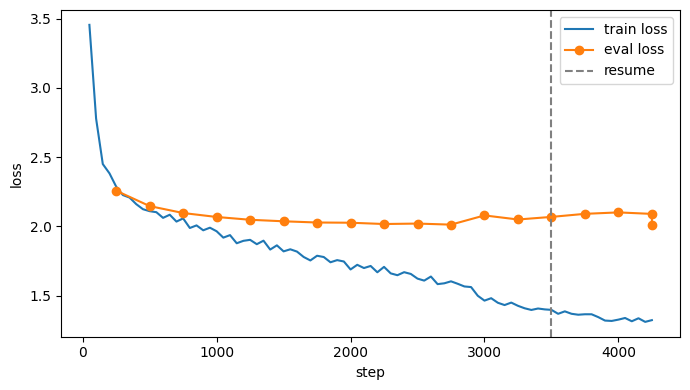

Adapter disimpan : Tesis_Pantun_SmolLM2_v3/models/lora_adapter_v3


In [12]:
# ── Cell 10: Training (otomatis lanjut dari checkpoint terakhir jika ada) ──
import os, re, glob
import matplotlib.pyplot as plt

CKPT_DIR = trainer.args.output_dir


def checkpoint_terakhir(folder):
    """Cari checkpoint-N dengan N terbesar yang file-nya lengkap."""
    kandidat = []
    for p in glob.glob(os.path.join(folder, "checkpoint-*")):
        m = re.search(r"checkpoint-(\d+)$", p)
        if m and os.path.exists(os.path.join(p, "trainer_state.json")):
            kandidat.append((int(m.group(1)), p))
    return max(kandidat)[1] if kandidat else None


resume_ckpt = checkpoint_terakhir(CKPT_DIR)
# Untuk memaksa checkpoint tertentu, isi manual, misalnya:
# resume_ckpt = f"{CKPT_DIR}/checkpoint-1500"

print("=" * 70)
if resume_ckpt:
    with open(os.path.join(resume_ckpt, "trainer_state.json")) as f:
        st = json.load(f)
    print(f"LANJUT dari  : {resume_ckpt}")
    print(f"Step / epoch : {st['global_step']} / {st.get('epoch', 0):.2f}")
    print(f"Best so far  : {st.get('best_metric')} ({st.get('best_model_checkpoint')})")
else:
    print(f"Tidak ada checkpoint di {CKPT_DIR}. Training dari awal.")
print("=" * 70)

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
train_result = trainer.train(resume_from_checkpoint=resume_ckpt)
durasi = time.time() - t0

m = train_result.metrics
eval_m = trainer.evaluate()

print("=" * 70)
print("TRAINING SELESAI")
print("=" * 70)
print(f"Durasi sesi ini   : {durasi / 3600:.2f} jam")
print(f"Train loss        : {m.get('train_loss', float('nan')):.4f}")
print(f"Eval loss terbaik : {trainer.state.best_metric}")
print(f"Eval loss akhir   : {eval_m.get('eval_loss', float('nan')):.4f}")
print(f"Checkpoint terbaik: {trainer.state.best_model_checkpoint}")
print(f"Peak VRAM         : {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

trainer.save_model(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

with open(f"{RESULTS_DIR}/training_log.json", "w") as f:
    json.dump({
        "model": MODEL_NAME,
        "config": {k: globals()[k] for k in [
            "LORA_R", "LORA_ALPHA", "LORA_DROPOUT", "LEARNING_RATE", "NUM_EPOCHS",
            "MICRO_BATCH", "GRAD_ACCUM", "MAX_LENGTH", "SEED"]},
        "resumed_from": resume_ckpt,
        "n_train_examples": len(train_ds),
        "n_val_examples": len(val_ds),
        "train_metrics": m,
        "eval_metrics": eval_m,
        "best_metric": trainer.state.best_metric,
        "best_model_checkpoint": trainer.state.best_model_checkpoint,
        "log_history": trainer.state.log_history,
    }, f, indent=2)

# Kurva loss (log_history ikut dipulihkan dari checkpoint, jadi kurvanya utuh)
hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
plt.figure(figsize=(7, 4))
if tr:
    plt.plot(*zip(*tr), label="train loss")
if ev:
    plt.plot(*zip(*ev), marker="o", label="eval loss")
if resume_ckpt:
    plt.axvline(st["global_step"], ls="--", c="gray", label="resume")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/loss_curve.png", dpi=150)
plt.show()

print(f"Adapter disimpan : {ADAPTER_DIR}")

## Cell 11: Fungsi Inference

Dipakai langsung setelah training (memakai `trainer.model`). Jika kernel di-restart, jalankan Cell 0, 2, 3, 4, 5, 7, lalu cell ini; model akan dimuat dari `ADAPTER_DIR`. Model base untuk pembanding diperoleh dengan menonaktifkan adapter sementara, jadi tidak perlu memuat dua model.

Tambahan v3: `rapikan_output` membuang baris `Rima:`, `ambil_rencana` membaca rencana rima, `generate_abab` memilih kandidat pertama yang lolos cek A-B-A-B, `seed_untuk` memberi seed berbeda per prompt.

In [11]:
import zlib

def _lora_terlatih(m):
    return any(p.detach().abs().sum().item() > 0 for n, p in m.named_parameters() if "lora_B" in n)


if "trainer" in globals() and _lora_terlatih(trainer.model):
    model = trainer.model
else:
    # trainer tidak ada, atau Cell 8-9 dijalankan tanpa Cell 10 (LoRA masih nol)
    for _n in ["trainer", "model"]:
        globals().pop(_n, None)
    gc.collect(); torch.cuda.empty_cache()
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.bfloat16, device_map={"": 0}, attn_implementation="sdpa")
    model = PeftModel.from_pretrained(base, ADAPTER_DIR)
    tokenizer = AutoTokenizer.from_pretrained(ADAPTER_DIR)
    IS_CHAT = tokenizer.chat_template is not None
model.eval()
model.config.use_cache = True
model.generation_config.use_cache = True
print("Adapter terlatih:", _lora_terlatih(model))

EOS_IDS = sorted({
    i for i in [tokenizer.eos_token_id,
                tokenizer.convert_tokens_to_ids("<|im_end|>"),
                tokenizer.convert_tokens_to_ids("<|endoftext|>")]
    if i is not None and i != tokenizer.unk_token_id
})

# GEN_CONFIG: max_new_tokens dinaikkan sedikit karena ada baris "Rima:" di awal
GEN_CONFIG["max_new_tokens"] = 112


def seed_untuk(label, offset=0):
    """Seed stabil dan berbeda per prompt (hash() Python berubah tiap sesi, crc32 tidak)."""
    return SEED + (zlib.crc32(label.encode("utf-8")) % 10_000) + offset


def build_prompt_text(instruction):
    """Format yang sama dengan saat training."""
    if IS_CHAT:
        return tokenizer.apply_chat_template(
            [{"role": "system", "content": SYSTEM_PROMPT},
             {"role": "user", "content": instruction}],
            tokenize=False, add_generation_prompt=True)
    return PLAIN_TEMPLATE.format(instruction=instruction)


@torch.inference_mode()
def generate(instruction, n=1, use_adapter=True, seed=SEED, **overrides):
    cfg = {**GEN_CONFIG, **overrides}
    inputs = tokenizer(build_prompt_text(instruction), return_tensors="pt",
                       add_special_tokens=not IS_CHAT).to(model.device)
    torch.manual_seed(seed)
    ctx = contextlib.nullcontext() if use_adapter else model.disable_adapter()
    with ctx:
        out = model.generate(**inputs, **cfg, num_return_sequences=n,
                             pad_token_id=tokenizer.pad_token_id, eos_token_id=EOS_IDS)
    n_in = inputs["input_ids"].shape[1]
    return [tokenizer.decode(seq[n_in:], skip_special_tokens=True).strip() for seq in out]


POLA_RENCANA = re.compile(r"^\s*rima\s*:\s*-?\s*([a-z]+)\s*/\s*-?\s*([a-z]+)", re.I)


def ambil_rencana(text):
    """Ambil rencana rima (A, B) dari output, jika ada."""
    for l in text.split("\n"):
        m = POLA_RENCANA.match(l)
        if m:
            return m.group(1).lower(), m.group(2).lower()
    return None


def rapikan_output(text):
    """Pisahkan baris, buang baris 'Rima:', label 'Pantun 4:', dan penomoran."""
    lines = []
    for l in text.split("\n"):
        l = l.strip()
        if not l or re.match(r"^rima\s*:", l, re.I):
            continue
        if re.match(r"^(pantun\s*\d*|sampiran|isi|contoh\s*\d*)\s*:?\s*$", l, re.I):
            continue
        l = re.sub(r"^(\d+[\.\)]|[-*])\s*", "", l)
        lines.append(normalisasi_baris(l))
    return [l for l in lines if l]


def lolos_abab(lines):
    ra, rb = cek_abab(lines)
    return len(lines) == 4 and ra and rb


def generate_abab(instruction, n_kandidat=20, seed=SEED, use_adapter=True, **kw):
    """
    Generate-then-filter: hasilkan n_kandidat, kembalikan yang pertama lolos
    cek A-B-A-B. Kembalikan (teks_mentah, lines, lolos, n_dicoba).
    n_dicoba = urutan kandidat terpilih; = n_kandidat jika tidak ada yang lolos.
    """
    outs = generate(instruction, n=n_kandidat, seed=seed, use_adapter=use_adapter, **kw)
    for k, teks in enumerate(outs, 1):
        lines = rapikan_output(teks)
        if lolos_abab(lines):
            return teks, lines, True, k
    # Tidak ada yang lolos: ambil kandidat pertama yang minimal 4 baris
    for teks in outs:
        lines = rapikan_output(teks)
        if len(lines) == 4:
            return teks, lines, False, n_kandidat
    return outs[0], rapikan_output(outs[0]), False, n_kandidat


print(f"Inference siap | EOS ids: {EOS_IDS} | chat template: {IS_CHAT}")

Loading weights: 100%|█| 218/218 [00:00<00:00, 272.57it/s, Materializing param=m


Adapter terlatih: True
Inference siap | EOS ids: [2] | chat template: True


## Cell 11b: Filter Rima v3 (Skor Rima Bertingkat + Validitas Kata + Rerank)

Setiap pasangan baris (1-3 dan 2-4) diberi skor 0-3 berdasarkan pemenggalan suku kata:

| Skor | Kriteria | Contoh |
|----|----|----|
| 3 | Suku terakhir identik dan vokal-koda suku kedua terakhir sama | men-ta-ri / di-ca-ri |
| 2 | Suku terakhir identik | ha-ri / be-ri |
| 1 | Vokal dan konsonan penutup suku terakhir sama | ma-kan / ja-lan |
| 0 | Tidak berima | |

Alur:
1. **Hasilkan** kandidat per batch 20; setiap sekuens berhenti setelah 4 baris. Berhenti lebih awal jika sudah ada 3 kandidat lolos penuh (maks 80).
2. **Potong** setiap kandidat menjadi tepat 4 baris (3-10 kata per baris).
3. **Skor heuristik** = 2 x (skor rima / 6) + proporsi kata valid + 0,5 x (semua kata akhir valid) - penalti kata rima identik - penalti pengulangan.
4. **Rerank** 8 kandidat teratas: skor akhir = skor heuristik - 0,5 x NLL model base (Ormazabal dkk., 2022).

Kamus: MALINDO Morph (Nomoto dkk., 2018), kolom kata dasar dan bentuk permukaan, ditambah kosakata train (frekuensi >= 2). Stopword: Tala (2003) via NLTK.

Sebelum lanjut ke Cell 12-13, pastikan hasil "Cek rencana rima" lebih dari 0/4.

In [12]:
# ══════════════════════════════════════════════════════════════════════
# Cell 11b (v3): Filter rima bertingkat + validitas kata + rerank NLL
# Jalankan setelah Cell 11. Cell 12 dan 13 tidak perlu diubah, karena
# generate_abab_v2 diarahkan ke generate_abab_v3 (signature sama).
# ══════════════════════════════════════════════════════════════════════
import glob
import subprocess
from functools import lru_cache
from transformers import StoppingCriteria, StoppingCriteriaList

# ── Parameter ─────────────────────────────────────────────────────────
MALINDO_DIR = "MALINDO_Morph"
MIN_FREQ = 2              # kosakata train minimal muncul 2 kali
MAX_OOV = 1               # maks kata tak dikenal agar "lolos_penuh"
MAX_ULANG = 2             # maks kemunculan satu kata isi
MIN_SKOR_PASANGAN = 1     # skor rima minimal per pasangan (0-3) agar lolos
N_PER_BATCH = 20          # kandidat per panggilan generate
MAKS_BATCH = 4            # batas atas: 4 x 20 = 80 kandidat
MIN_LOLOS = 3             # berhenti lebih awal jika sudah ada 3 kandidat lolos penuh
TOPK_NLL = 8              # hanya top-k (skor heuristik) yang dinilai NLL
BOBOT_NLL = 0.5           # bobot NLL dalam skor akhir
SKOR_DENGAN_BASE = True   # NLL dinilai model base (adapter nonaktif)
MAX_NEW_TOKENS_V3 = 80    # pantun 4 baris + baris "Rima:" cukup < 80 token

# ── 0. Pastikan adapter yang dipakai benar-benar hasil training ──────
# LoRA diinisialisasi dengan lora_B = 0. Jika normanya 0, model yang aktif
# identik dengan model base (misalnya Cell 8-9 dijalankan tetapi Cell 10 tidak).
def norma_lora_B(m):
    tot = 0.0
    for n, p in m.named_parameters():
        if "lora_B" in n:
            tot += p.detach().float().norm().item() ** 2
    return tot ** 0.5


if norma_lora_B(model) == 0.0:
    print(f"PERINGATAN: adapter di memori belum terlatih (lora_B = 0). Memuat ulang dari {ADAPTER_DIR}")
    del model
    globals().pop("trainer", None)
    gc.collect(); torch.cuda.empty_cache()
    _base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.bfloat16, device_map={"": 0}, attn_implementation="sdpa")
    model = PeftModel.from_pretrained(_base, ADAPTER_DIR)
    model.eval()
print(f"Norma lora_B  : {norma_lora_B(model):.3f} (harus > 0)")

# KV cache wajib aktif saat inference (trainer bisa mematikannya)
model.config.use_cache = True
model.generation_config.use_cache = True

# ── 1. Kamus MALINDO Morph ────────────────────────────────────────────
if not os.path.isdir(MALINDO_DIR):
    r = subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/matbahasa/MALINDO_Morph.git", MALINDO_DIR],
                       capture_output=True, text=True)
    print("git clone MALINDO:", "berhasil" if r.returncode == 0 else r.stderr.strip()[:300])


def muat_malindo(folder):
    """
    Hanya kolom kata dasar (kolom ke-2) dan bentuk permukaan (kolom ke-3) yang diambil.
    Versi lama mengambil SEMUA token di setiap baris (termasuk label afiks dan kode
    sumber), sehingga kata rekaan seperti "ilmi" dan "cerat" ikut dianggap valid.
    Cek urutan kolom sekali dengan: !head -3 MALINDO_Morph/*.tsv
    """
    kata = set()
    files = [p for p in glob.glob(f"{folder}/**/*", recursive=True)
             if p.lower().endswith((".tsv", ".txt", ".csv")) and "readme" not in p.lower()]
    for path in files:
        with open(path, encoding="utf-8", errors="ignore") as f:
            for baris in f:
                kol = baris.rstrip("\n").split("\t")
                for c in kol[1:3]:
                    c = c.strip().lower()
                    if re.fullmatch(r"[a-z]+(?:-[a-z]+)*", c):
                        kata.update(w for w in c.split("-") if len(w) >= 2)
    return kata, len(files)


MALINDO, n_file = muat_malindo(MALINDO_DIR)
print(f"MALINDO Morph : {len(MALINDO):,} bentuk kata dari {n_file} file")
if len(MALINDO) < 10_000:
    print("PERINGATAN: kamus terlalu kecil, kemungkinan urutan kolom berbeda. Cek file TSV-nya.")

VOCAB = Counter(w for p in train_pantun for l in p for w in re.findall(r"[a-z]+", l.lower()))
PARTIKEL = ("lah", "kah", "pun", "nya", "ku", "mu")


@lru_cache(maxsize=None)
def kata_valid(w):
    if w in MALINDO or VOCAB[w] >= MIN_FREQ:
        return True
    for akhiran in PARTIKEL:
        if w.endswith(akhiran) and len(w) - len(akhiran) >= 3:
            dasar = w[: -len(akhiran)]
            if dasar in MALINDO or VOCAB[dasar] >= MIN_FREQ:
                return True
    return False


import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
STOPWORDS_FILTER = set(stopwords.words("indonesian")) | {
    "sih", "dong", "deh", "kok", "banget", "biar", "bikin",
    "adik", "abang", "kakak", "tuan", "nona", "dinda", "kanda", "hati"}

# ── 2. Pemenggalan suku kata dan skor rima bertingkat (0-3) ──────────
_DIGRAF = (("ng", "N"), ("ny", "Y"), ("sy", "S"), ("kh", "K"))
_BALIK = {b: a for a, b in _DIGRAF}


def suku_kata(w):
    """Pemenggalan sederhana bahasa Indonesia: mentari -> men-ta-ri, pantai -> pan-tai."""
    s = w.lower()
    for a, b in _DIGRAF:
        s = s.replace(a, b)
    nukleus, i = [], 0
    while i < len(s):
        if s[i] in "aiueo":
            j = i + 1
            if j < len(s) and s[i:j + 1] in ("ai", "au", "oi") and j + 1 == len(s):
                j += 1   # diftong di akhir kata: pan-tai, pu-lau
            nukleus.append((i, j))
            i = j
        else:
            i += 1
    if not nukleus:
        return [w.lower()]
    batas = [0]
    for (_, a1), (b0, _) in zip(nukleus, nukleus[1:]):
        batas.append(a1 if b0 - a1 <= 1 else a1 + 1)   # V-CV atau VC-CV
    batas.append(len(s))
    return ["".join(_BALIK.get(c, c) for c in s[x:y]) for x, y in zip(batas, batas[1:])]


def _rima_suku(sk):
    m = re.search(r"[aiueo].*$", sk)
    return m.group(0) if m else sk


def skor_rima_pasangan(w1, w2):
    """
    3 : suku terakhir identik + vokal-koda suku kedua terakhir sama (men-ta-ri / di-ca-ri)
    2 : suku terakhir identik                                        (ha-ri / be-ri)
    1 : vokal + konsonan penutup suku terakhir sama                   (ma-kan / ja-lan)
    0 : tidak berima
    """
    if not w1 or not w2:
        return 0
    s1, s2 = suku_kata(w1), suku_kata(w2)
    if s1[-1] == s2[-1]:
        if len(s1) > 1 and len(s2) > 1 and _rima_suku(s1[-2]) == _rima_suku(s2[-2]):
            return 3
        return 2
    return 1 if _rima_suku(s1[-1]) == _rima_suku(s2[-1]) else 0


def skor_rima_pantun(lines):
    """Kembalikan (skor_A, skor_B), masing-masing 0-3."""
    a = [kata_akhir(l) for l in lines]
    return skor_rima_pasangan(a[0], a[2]), skor_rima_pasangan(a[1], a[3])


# ── 3. Pertahankan 4 baris ────────────────────────────────────────────
def ambil_4_baris(teks):
    """Ambil 4 baris pertama yang bersih. None jika < 4 baris atau panjang baris di luar 3-10 kata."""
    lines = rapikan_output(teks)
    if len(lines) < 4:
        return None
    lines = lines[:4]
    if not all(3 <= len(l.split()) <= 10 for l in lines):
        return None
    return lines


# ── 4. Penilaian kandidat (skor kontinu, bukan biner) ────────────────
def nilai_kandidat(lines):
    sA, sB = skor_rima_pantun(lines)
    akhir = [kata_akhir(l) for l in lines]
    kata = [w for l in lines for w in re.findall(r"[a-z]+", l.lower())]
    n_oov = sum(not kata_valid(w) for w in kata)
    prop_valid = 1 - n_oov / max(len(kata), 1)
    akhir_ok = all(kata_valid(w) for w in akhir)
    kata_sama = akhir[0] == akhir[2] or akhir[1] == akhir[3]
    isi = Counter(w for w in kata if w not in STOPWORDS_FILTER and len(w) > 3)
    ulang = bool(isi) and isi.most_common(1)[0][1] > MAX_ULANG

    alasan = []
    if min(sA, sB) < MIN_SKOR_PASANGAN: alasan.append("rima")
    if not akhir_ok:                    alasan.append("kata_akhir_tidak_valid")
    if kata_sama:                       alasan.append("rima_kata_sama")
    if n_oov > MAX_OOV:                 alasan.append("kata_tidak_dikenal")
    if ulang:                           alasan.append("pengulangan")

    skor = (2.0 * (sA + sB) / 6 + 1.0 * prop_valid + 0.5 * akhir_ok
            - 1.0 * kata_sama - 0.5 * ulang)
    return {"skor_A": sA, "skor_B": sB, "skor_heuristik": skor,
            "lolos_penuh": not alasan, "alasan": alasan}


# ── 5. Generasi cepat: berhenti per sekuens setelah 4 baris ──────────
NEWLINE_IDS = torch.tensor(
    [i for i in range(len(tokenizer)) if "\n" in tokenizer.decode([i])], device=model.device)


class BerhentiSetelahBaris(StoppingCriteria):
    """Hentikan setiap sekuens begitu jumlah baris baru cukup (Rima + 4 baris)."""
    def __init__(self, n_prompt, n_newline):
        self.n_prompt, self.n_newline = n_prompt, n_newline

    def __call__(self, input_ids, scores, **kw):
        gen = input_ids[:, self.n_prompt:]
        return torch.isin(gen, NEWLINE_IDS).sum(dim=1) >= self.n_newline


@torch.inference_mode()
def generate_kandidat(instruction, n, seed, use_adapter=True):
    inputs = tokenizer(build_prompt_text(instruction), return_tensors="pt",
                       add_special_tokens=not IS_CHAT).to(model.device)
    n_in = inputs["input_ids"].shape[1]
    cfg = {**GEN_CONFIG, "max_new_tokens": MAX_NEW_TOKENS_V3}
    stop = StoppingCriteriaList([BerhentiSetelahBaris(n_in, 5 if USE_RHYME_PLAN else 4)])
    torch.manual_seed(seed)
    ctx = contextlib.nullcontext() if use_adapter else model.disable_adapter()
    with ctx:
        out = model.generate(**inputs, **cfg, num_return_sequences=n, use_cache=True,
                             stopping_criteria=stop, pad_token_id=tokenizer.pad_token_id,
                             eos_token_id=EOS_IDS)
    return [tokenizer.decode(s[n_in:], skip_special_tokens=True).strip() for s in out]


# ── 6. NLL dalam batch (bukan satu per satu) ─────────────────────────
@torch.inference_mode()
def skor_nll_batch(instruction, daftar_lines, pakai_base=SKOR_DENGAN_BASE, bs=16):
    p_ids = tokenizer(build_prompt_text(instruction), add_special_tokens=not IS_CHAT)["input_ids"]
    n_p = len(p_ids)
    ctx = model.disable_adapter() if pakai_base else contextlib.nullcontext()
    hasil = []
    with ctx:
        for k in range(0, len(daftar_lines), bs):
            seqs = []
            for lines in daftar_lines[k:k + bs]:
                teks = "\n".join(lines) if pakai_base else target_pantun(lines)
                seqs.append(p_ids + tokenizer(teks, add_special_tokens=False)["input_ids"])
            L = max(map(len, seqs))
            ids = torch.full((len(seqs), L), tokenizer.pad_token_id)
            att = torch.zeros_like(ids)
            lab = torch.full_like(ids, -100)
            for r, s in enumerate(seqs):
                ids[r, :len(s)] = torch.tensor(s)
                att[r, :len(s)] = 1
                lab[r, n_p:len(s)] = torch.tensor(s[n_p:])
            ids, att, lab = ids.to(model.device), att.to(model.device), lab.to(model.device)
            logits = model(input_ids=ids, attention_mask=att).logits.float()
            nll = torch.nn.functional.cross_entropy(
                logits[:, :-1].transpose(1, 2), lab[:, 1:], ignore_index=-100, reduction="none")
            n_tok = (lab[:, 1:] != -100).sum(1).clamp(min=1)
            hasil += (nll.sum(1) / n_tok).tolist()
    return hasil


# ── 7. Generate-then-rank v3 ──────────────────────────────────────────
def generate_abab_v3(instruction, n_kandidat=None, seed=SEED, pakai_base=SKOR_DENGAN_BASE, **kw):
    """
    1. Hasilkan kandidat per batch 20, berhenti lebih awal jika sudah ada MIN_LOLOS yang lolos penuh.
    2. Setiap kandidat dipotong ke 4 baris dan diberi skor kontinu (rima 0-6, validitas kata, penalti).
    3. Top-k dinilai NLL model base; skor akhir = skor_heuristik - BOBOT_NLL * NLL.
    Output selalu 4 baris selama ada satu kandidat dengan 4 baris layak.
    Kembalikan (teks, lines, lolos_penuh, n_lolos_penuh, statistik) seperti v2.
    """
    maks_batch = MAKS_BATCH if n_kandidat is None else max(1, math.ceil(n_kandidat / N_PER_BATCH))
    semua, statistik, raw_pertama = [], Counter(), None
    for b in range(maks_batch):
        for teks in generate_kandidat(instruction, N_PER_BATCH, seed + 1000 * b):
            raw_pertama = raw_pertama or teks
            lines = ambil_4_baris(teks)
            if lines is None:
                statistik["struktur"] += 1
                continue
            info = nilai_kandidat(lines)
            statistik.update(info["alasan"] or ["lolos"])
            semua.append((teks, lines, info))
        if sum(x[2]["lolos_penuh"] for x in semua) >= MIN_LOLOS:
            break
    statistik["n_dicoba"] = (b + 1) * N_PER_BATCH

    if not semua:   # sangat jarang: tidak ada satu pun kandidat 4 baris
        return raw_pertama, rapikan_output(raw_pertama)[:4], False, 0, statistik

    n_lolos = sum(x[2]["lolos_penuh"] for x in semua)
    pool = [x for x in semua if x[2]["lolos_penuh"]] or semua
    pool = sorted(pool, key=lambda x: -x[2]["skor_heuristik"])[:TOPK_NLL]
    nll = skor_nll_batch(instruction, [x[1] for x in pool], pakai_base=pakai_base)
    akhir = [x[2]["skor_heuristik"] - BOBOT_NLL * v for x, v in zip(pool, nll)]
    raw, lines, info = pool[int(np.argmax(akhir))]

    # Teks bersih: rencana rima (jika ada) + tepat 4 baris, supaya metrik Cell 13 konsisten
    rencana = ambil_rencana(raw)
    teks = (f"Rima: -{rencana[0]} / -{rencana[1]}\n" if rencana else "") + "\n".join(lines)
    return teks, lines, info["lolos_penuh"], n_lolos, statistik


generate_abab_v2 = generate_abab_v3   # Cell 12 dan 13 tetap jalan tanpa diubah

# ── 8. Uji cepat ──────────────────────────────────────────────────────
print("\nUji suku kata dan skor rima:")
for w1, w2 in [("mentari", "dicari"), ("hari", "beri"), ("makan", "jalan"), ("durinya", "mulia"), ("kopi", "hebat")]:
    print(f"  {w1:<9} {w2:<9} {'-'.join(suku_kata(w1)):<10} {'-'.join(suku_kata(w2)):<10} skor {skor_rima_pasangan(w1, w2)}")

print("\nUji kata (atas harus True, bawah sebaiknya False):")
for w in ["membaca", "dimaafkan", "rajinlah", "berbunga", "nian", "ilmi", "cerat", "janggang", "sembarana", "imternas"]:
    print(f"  {w:<11} {kata_valid(w)}")

print("\nCek rencana rima pada prompt training (harus muncul 'Rima:'):")
_outs = generate_kandidat(FULL_ZERO_TRAIN[0], 4, SEED)
print(f"  {sum(ambil_rencana(o) is not None for o in _outs)}/4 output memuat 'Rima:'")

for nama, prompt in [("zero_shot", ZERO_SHOT_PROMPT), ("few_shot", FEW_SHOT_PROMPT)]:
    t0 = time.time()
    teks, lines, penuh, n_lolos, st = generate_abab_v3(prompt, seed=seed_untuk(f"uji_v3|{nama}"))
    print(f"\n[{nama}] lolos_penuh={penuh} | lolos {n_lolos}/{st['n_dicoba']} | "
          f"skor rima {skor_rima_pantun(lines)} | {time.time() - t0:.1f} s")
    print("\n".join(lines))


Norma lora_B  : 17.930 (harus > 0)
MALINDO Morph : 162,115 bentuk kata dari 12 file

Uji suku kata dan skor rima:
  mentari   dicari    men-ta-ri  di-ca-ri   skor 3
  hari      beri      ha-ri      be-ri      skor 2
  makan     jalan     ma-kan     ja-lan     skor 1
  durinya   mulia     du-ri-nya  mu-li-a    skor 1
  kopi      hebat     ko-pi      he-bat     skor 0

Uji kata (atas harus True, bawah sebaiknya False):
  membaca     True
  dimaafkan   True
  rajinlah    True
  berbunga    True
  nian        True
  ilmi        True
  cerat       True
  janggang    False
  sembarana   True
  imternas    False

Cek rencana rima pada prompt training (harus muncul 'Rima:'):
  4/4 output memuat 'Rima:'

[zero_shot] lolos_penuh=True | lolos 3/80 | skor rima (2, 1) | 31.8 s
Supaya hidup jadi sehatkan
Jangan lupa memakai selalu batangan
Menjaga integritas jangan dilupakan
Agar hidup tetap sehatkan

[few_shot] lolos_penuh=True | lolos 5/60 | skor rima (1, 1) | 30.0 s
Hati hati maintengan bersama
M

## Cell 12: Demo
Prompt Tabel 3.18, Tabel 3.19, dan prompt bertema. Setiap prompt dibandingkan: tanpa filter, filter v1, dan filter v3.

In [17]:
DEMO_PROMPTS = {
    "Tabel 3.18 (zero-shot)": ZERO_SHOT_PROMPT,
    "Tabel 3.19 (few-shot)": FEW_SHOT_PROMPT,
    "tema: semangat belajar": "Buatkan pantun tentang semangat belajar",
    "tema: menghormati orang tua": "Buatkan pantun nasihat tentang menghormati orang tua",
    "tema: kucing": "Buatkan pantun jenaka tentang kucing",
    "tema: cinta tanah air": "Buatkan pantun cinta tanah air",
}

for nama, prompt in DEMO_PROMPTS.items():
    s = seed_untuk(nama)
    print("=" * 70)
    print(nama)
    print("=" * 70)

    print(">> Fine-tuned (tanpa filter)")
    for i, teks in enumerate(generate(prompt, n=3, seed=s), 1):
        lines = rapikan_output(teks)
        rencana = ambil_rencana(teks)
        print(f"[{i}] rencana: {rencana} | 4 baris: {len(lines) == 4} | A-B-A-B: {lolos_abab(lines)}")
        print("\n".join(lines))
        print("-" * 70)

    print(">> Fine-tuned + filter rima")
    _, lines, lolos, k = generate_abab(prompt, n_kandidat=20, seed=s + 1)
    print(f"lolos: {lolos} | kandidat ke-{k}")
    print("\n".join(lines))
    print("-" * 70)

    print(">> Fine-tuned + filter v3 (skor rima 0-3 + validitas kata + rerank)")
    t0 = time.time()
    _, lines, penuh, n_lolos, st = generate_abab_v3(prompt, seed=s + 2)
    print(f"lolos_penuh: {penuh} | lolos {n_lolos}/{st['n_dicoba']} | "
          f"skor rima (A, B): {skor_rima_pantun(lines)} | {time.time() - t0:.1f} s")
    print("\n".join(lines))
    print("-" * 70)


Tabel 3.18 (zero-shot)
>> Fine-tuned (tanpa filter)
[1] rencana: ('an', 'an') | 4 baris: True | A-B-A-B: False
Ke toko beli piring dan ikan
Niscaya jadi kopra larilari nian
Sebab insan biadab akan merugi
Dari zaman mendengarkan orangnya
----------------------------------------------------------------------
[2] rencana: ('ang', 'in') | 4 baris: True | A-B-A-B: False
Setiap kesekian usia kecil
Pastinya malas akan mendalam saja
Hati ingin membeli gelang
Walau tiada ada yang punya
----------------------------------------------------------------------
[3] rencana: ('u', 'ang') | 4 baris: True | A-B-A-B: False
Membaca alquran selalu lagi hargai ilmu
Ilmu boleh jadi ruang ibadah guruku
Jika ingin hidup selamat diri
Engkaulah ramai orang yang membantu
----------------------------------------------------------------------
>> Fine-tuned + filter rima
lolos: True | kandidat ke-7
Jalanjalan ke pasar malaka
Naik motor indah warnanya
Hatihatilah akan suami yang cinta
Jangan lupa berbaca doa
--------

## Cell 13: Evaluasi Otomatis (Base vs Fine-tuned vs Filter v1 vs Filter v3, Zero-shot vs Few-shot)

Metrik per pantun:

- `struktur_4`: output tepat 4 baris.
- `rima_a`, `rima_b`, `rima_abab`: bunyi akhir baris 1 dan 3, serta 2 dan 4 sama (pendekatan vokal terakhir + konsonan penutup).
- `panjang_ok`: setiap baris 3-10 kata.
- `salin_pantun`: pantun sama persis dengan pantun di data train (hafalan).
- `baris_dari_train`: proporsi baris yang sama persis dengan baris di data train.
- `salin_contoh`: ada baris yang disalin dari contoh few-shot.
- `ada_rencana`: output memuat baris `Rima:`.
- `patuh_rencana`: bunyi akhir keempat baris sesuai rencana rima.
- `kata_valid`: proporsi kata yang ada di MALINDO Morph atau kosakata train.
- `akhir_valid`: keempat kata akhir baris valid (kata rima bukan kata rekaan).
- `semua_valid`: seluruh kata dalam pantun valid.
- `skor_rima`: skor rima bertingkat (A + B) / 6, rentang 0-1.
- `lolos_penuh_v2`, `rerata_lolos_v2`: untuk filter v3, proporsi pantun yang lolos semua syarat dan rata-rata kandidat yang lolos.
- `rerata_kandidat`: rata-rata kandidat yang dicoba (bermakna untuk `fine_tuned_filter`).
- `distinct_2`: keragaman bigram antar-pantun dalam satu konfigurasi.

Hasil disimpan ke `RESULTS_DIR` dan bisa langsung dipakai untuk uji statistik serta evaluasi manusia pada notebook lama.

In [14]:
N_SAMPLES = 100     # pantun per kombinasi model x prompt
BATCH = 10          # num_return_sequences per panggilan (tanpa filter)
N_KANDIDAT = 20     # kandidat per pantun untuk konfigurasi filter v1
# Filter v3: maks MAKS_BATCH x N_PER_BATCH kandidat dengan early exit (Cell 11b)


def nilai_output(teks):
    lines = rapikan_output(teks)
    ra, rb = cek_abab(lines)
    keys = [kunci_teks(l) for l in lines]
    kata = [w for l in lines for w in re.findall(r"[a-z]+", l.lower())]
    rencana = ambil_rencana(teks)
    patuh = None
    if rencana and len(lines) == 4:
        patuh = (rima_key(lines[0]) == rencana[0] and rima_key(lines[2]) == rencana[0]
                 and rima_key(lines[1]) == rencana[1] and rima_key(lines[3]) == rencana[1])
    sA, sB = skor_rima_pantun(lines) if len(lines) == 4 else (0, 0)
    return {
        "n_baris": len(lines),
        "skor_rima": (sA + sB) / 6,
        "struktur_4": len(lines) == 4,
        "rima_a": ra,
        "rima_b": rb,
        "rima_abab": ra and rb,
        "panjang_ok": len(lines) == 4 and all(3 <= len(l.split()) <= 10 for l in lines),
        "salin_pantun": " | ".join(keys) in TRAIN_PANTUN_KEYS,
        "baris_dari_train": float(np.mean([k in TRAIN_LINE_KEYS for k in keys])) if keys else 0.0,
        "salin_contoh": any(k in FEW_SHOT_LINE_KEYS for k in keys),
        "ada_rencana": rencana is not None,
        "patuh_rencana": patuh,          # None jika tidak ada rencana
        "kata_valid": float(np.mean([kata_valid(w) for w in kata])) if kata else 0.0,
        "akhir_valid": len(lines) == 4 and all(kata_valid(kata_akhir(l)) for l in lines),
        "semua_valid": bool(kata) and all(kata_valid(w) for w in kata),
        "pantun": "\n".join(lines),
    }


def distinct_n(texts, n=2):
    grams = [tuple(t.lower().split()[i:i + n]) for t in texts
             for i in range(len(t.lower().split()) - n + 1)]
    return len(set(grams)) / len(grams) if grams else 0.0


rows = []

# 1) Base dan fine-tuned tanpa filter
for model_type, use_adapter in [("base", False), ("fine_tuned", True)]:
    for prompt_key, prompt in EVAL_PROMPTS.items():
        t0 = time.time()
        for b in range(N_SAMPLES // BATCH):
            s = seed_untuk(f"{model_type}|{prompt_key}", offset=b)
            outs = generate(prompt, n=BATCH, use_adapter=use_adapter, seed=s)
            for j, teks in enumerate(outs):
                rows.append({"model_type": model_type, "prompt_key": prompt_key,
                             "sample_idx": b * BATCH + j, "raw_output": teks,
                             "n_dicoba": 1, **nilai_output(teks)})
        print(f"{model_type:<18} | {prompt_key:<9} | {time.time() - t0:6.1f} s")

# 2) Fine-tuned + filter rima (generate-then-filter)
for prompt_key, prompt in EVAL_PROMPTS.items():
    t0 = time.time()
    for i in range(N_SAMPLES):
        s = seed_untuk(f"filter|{prompt_key}", offset=i)
        teks, _, _, k = generate_abab(prompt, n_kandidat=N_KANDIDAT, seed=s)
        rows.append({"model_type": "fine_tuned_filter", "prompt_key": prompt_key,
                     "sample_idx": i, "raw_output": teks, "n_dicoba": k,
                     **nilai_output(teks)})
    print(f"{'fine_tuned_filter':<18} | {prompt_key:<9} | {time.time() - t0:6.1f} s")

# 3) Fine-tuned + filter v3 (skor rima 0-3 + validitas kata + rerank NLL)
alasan_v2 = Counter()
for prompt_key, prompt in EVAL_PROMPTS.items():
    t0 = time.time()
    for i in range(N_SAMPLES):
        s = seed_untuk(f"filter_v2|{prompt_key}", offset=i)
        teks, _, penuh, n_lolos, st = generate_abab_v3(prompt, seed=s)
        n_dicoba = st.pop("n_dicoba")
        alasan_v2.update(st)
        rows.append({"model_type": "fine_tuned_filter_v3", "prompt_key": prompt_key,
                     "sample_idx": i, "raw_output": teks, "n_dicoba": n_dicoba,
                     "n_lolos_penuh": n_lolos, "lolos_penuh": penuh,
                     **nilai_output(teks)})
    print(f"{'fine_tuned_filter_v3':<20} | {prompt_key:<9} | {time.time() - t0:6.1f} s")

tot = sum(alasan_v2.values())
print("\nAlasan kandidat gagal di filter v3 (seluruh kandidat):")
for k, v in alasan_v2.most_common():
    print(f"  {k:<24}: {v:6,} ({v / tot:5.1%})")

eval_df = pd.DataFrame(rows)
eval_df.to_csv(f"{RESULTS_DIR}/evaluasi_otomatis.csv", index=False, encoding="utf-8")

kolom = ["struktur_4", "rima_a", "rima_b", "rima_abab", "skor_rima", "panjang_ok",
         "kata_valid", "akhir_valid", "semua_valid",
         "salin_pantun", "baris_dari_train", "salin_contoh", "ada_rencana"]
grup = eval_df.groupby(["model_type", "prompt_key"])
ringkas = grup[kolom].mean().round(3)
ringkas["patuh_rencana"] = grup["patuh_rencana"].apply(
    lambda s: round(s.dropna().astype(float).mean(), 3) if s.notna().any() else np.nan)
ringkas["distinct_2"] = grup["pantun"].apply(lambda s: round(distinct_n(list(s)), 3))
ringkas["rerata_kandidat"] = grup["n_dicoba"].mean().round(2)
if "lolos_penuh" in eval_df:
    ringkas["lolos_penuh_v2"] = grup["lolos_penuh"].apply(
        lambda s: round(s.dropna().astype(float).mean(), 3) if s.notna().any() else np.nan)
    ringkas["rerata_lolos_v2"] = grup["n_lolos_penuh"].mean().round(2)
ringkas.to_csv(f"{RESULTS_DIR}/ringkasan_evaluasi.csv", encoding="utf-8")

print("\n" + "=" * 70)
print("RINGKASAN (proporsi)")
print("=" * 70)
print(ringkas.to_string())

for (mt, pk), g in grup:
    print("\n" + "=" * 70)
    print(f"CONTOH: {mt} | {pk}")
    print("=" * 70)
    for teks in g["pantun"].head(3):
        print(teks)
        print("-" * 70)

with open(f"{RESULTS_DIR}/prompt_evaluasi.json", "w", encoding="utf-8") as f:
    json.dump({"prompts": EVAL_PROMPTS, "few_shot_examples": FEW_SHOT_EXAMPLES,
               "gen_config": GEN_CONFIG, "n_samples": N_SAMPLES,
               "n_kandidat_filter": N_KANDIDAT, "n_kandidat_filter_v3": {"per_batch": N_PER_BATCH, "maks_batch": MAKS_BATCH, "min_lolos": MIN_LOLOS},
               "filter_v3": {"skor_rima": "bertingkat 0-3 per pasangan (suku kata)", "min_skor_pasangan": MIN_SKOR_PASANGAN,
                             "bobot_nll": BOBOT_NLL, "topk_nll": TOPK_NLL,
                             "kamus": "MALINDO Morph (Nomoto dkk., 2018)",
                             "n_kata_kamus": len(MALINDO), "min_freq_vocab_train": MIN_FREQ,
                             "max_oov": MAX_OOV, "max_ulang": MAX_ULANG,
                             "stopword": "Tala (2003) via NLTK + tambahan pantun",
                             "rerank": "NLL model base" if SKOR_DENGAN_BASE else "NLL model fine-tuned"},
               "seed": SEED,
               "use_rhyme_plan": USE_RHYME_PLAN},
              f, ensure_ascii=False, indent=2)
print(f"\nHasil disimpan di {RESULTS_DIR}")

base               | zero_shot |   30.3 s
base               | few_shot  |   34.3 s
fine_tuned         | zero_shot |   33.1 s
fine_tuned         | few_shot  |   38.7 s
fine_tuned_filter  | zero_shot |  408.5 s
fine_tuned_filter  | few_shot  |  473.7 s
fine_tuned_filter_v3 | few_shot  | 1115.3 s

Alasan kandidat gagal di filter v3 (seluruh kandidat):
  rima                    :  8,861 (49.7%)
  kata_akhir_tidak_valid  :  5,280 (29.6%)
  kata_tidak_dikenal      :  2,556 (14.3%)
  lolos                   :    657 ( 3.7%)
  rima_kata_sama          :    215 ( 1.2%)
  struktur                :    126 ( 0.7%)
  pengulangan             :    119 ( 0.7%)

RINGKASAN (proporsi)
                                 struktur_4  rima_a  rima_b  rima_abab  skor_rima  panjang_ok  kata_valid  akhir_valid  semua_valid  salin_pantun  baris_dari_train  salin_contoh  ada_rencana  patuh_rencana  distinct_2  rerata_kandidat  lolos_penuh_v2  rerata_lolos_v2
model_type           prompt_key                          

In [ ]:
# ── Cell 13b: Ekspor hasil evaluasi agar mudah dibaca ─────────────────
df_baca = pd.read_csv(f"{RESULTS_DIR}/evaluasi_otomatis.csv")

hasil = {}
for (mt, pk), g in df_baca.groupby(["model_type", "prompt_key"], sort=False):
    hasil.setdefault(mt, {})[pk] = [{
        "sample_idx": int(r.sample_idx),
        "raw_output": str(r.raw_output).split("\n"),
        "pantun": str(r.pantun).split("\n") if isinstance(r.pantun, str) else [],
        "struktur_4": bool(r.struktur_4),
        "rima_abab": bool(r.rima_abab),
        "skor_rima": round(float(r.skor_rima), 3),
        "semua_valid": bool(r.semua_valid),
    } for r in g.itertuples()]

with open(f"{RESULTS_DIR}/evaluasi_otomatis_rapi.json", "w", encoding="utf-8") as f:
    json.dump(hasil, f, ensure_ascii=False, indent=2)

with open(f"{RESULTS_DIR}/evaluasi_otomatis_rapi.txt", "w", encoding="utf-8") as f:
    for mt, per_prompt in hasil.items():
        for pk, rows_baca in per_prompt.items():
            f.write("=" * 70 + f"\n{mt} | {pk}\n" + "=" * 70 + "\n")
            for r in rows_baca:
                f.write(f"[#{r['sample_idx']}] 4baris={r['struktur_4']} abab={r['rima_abab']} "
                        f"skor_rima={r['skor_rima']} valid={r['semua_valid']}\n")
                f.write("\n".join(r["raw_output"]) + "\n" + "-" * 70 + "\n")

print(f"Disimpan: {RESULTS_DIR}/evaluasi_otomatis_rapi.json dan .txt")

In [15]:
# ── Cell 14: Metrik Siallagan & Alfina (2023) ─────────────────────────
# Structure Accuracy, Rhyme Correctness, Lexical Richness
# Butuh: suku_kata (Cell 11b), kata_akhir (Cell 3)

ev = pd.read_csv(f"{RESULTS_DIR}/evaluasi_otomatis.csv")
ev["pantun"] = ev["pantun"].fillna("").astype(str)


def ke_baris(teks):
    return [l.strip() for l in str(teks).split("\n") if l.strip()]


def structure_correct(teks):
    """Pantun benar jika terdiri dari tepat 4 baris (2 sampiran + 2 isi)."""
    return len(ke_baris(teks)) == 4


def vokal_akhir(w):
    """Vokal terakhir pada suku kata terakhir kata akhir baris."""
    if not w:
        return ""
    v = re.findall(r"[aiueo]", suku_kata(w)[-1])
    return v[-1] if v else ""


def rhyme_correct(teks):
    """Algoritma 1: vokal akhir baris 1 = baris 3 dan baris 2 = baris 4."""
    L = ke_baris(teks)
    if len(L) != 4:
        return False
    v = [vokal_akhir(kata_akhir(l)) for l in L]
    return bool(v[0]) and v[0] == v[2] and bool(v[1]) and v[1] == v[3]


def lexical_richness(daftar_teks):
    """Herdan C = log(V) / log(N), V = jumlah kata unik, N = jumlah seluruh kata."""
    tok = [w for t in daftar_teks for w in re.findall(r"[a-z]+", t.lower())]
    return math.log(len(set(tok))) / math.log(len(tok)) if len(tok) > 1 else float("nan")


ev["structure_correct"] = ev["pantun"].apply(structure_correct)
ev["rhyme_correct"] = ev["pantun"].apply(rhyme_correct)

grup = ev.groupby(["model_type", "prompt_key"], sort=False)
tabel = pd.DataFrame({
    "Structure Accuracy (%)": (grup["structure_correct"].mean() * 100).round(2),
    "Rhyme Correctness (%)": (grup["rhyme_correct"].mean() * 100).round(2),
    "Lexical Richness": grup["pantun"].apply(lambda s: round(lexical_richness(list(s)), 3)),
    "n": grup.size(),
})
tabel.to_csv(f"{RESULTS_DIR}/metrik_siallagan_alfina.csv", encoding="utf-8")

print("=" * 70)
print("METRIK SIALLAGAN & ALFINA (2023)")
print("Pembanding paper: GPT-2 = 99,50% / 49,70% / 0,78")
print("=" * 70)
print(tabel.to_string())

METRIK SIALLAGAN & ALFINA (2023)
Pembanding paper: GPT-2 = 99,50% / 49,70% / 0,78
                                 Structure Accuracy (%)  Rhyme Correctness (%)  Lexical Richness    n
model_type           prompt_key                                                                      
base                 zero_shot                     29.0                    4.0             0.854  100
                     few_shot                      23.0                    3.0             0.867  100
fine_tuned           zero_shot                    100.0                   51.0             0.892  100
                     few_shot                     100.0                   44.0             0.898  100
fine_tuned_filter    zero_shot                    100.0                   95.0             0.893  100
                     few_shot                     100.0                   98.0             0.892  100
fine_tuned_filter_v3 zero_shot                    100.0                  100.0             0.879  100


In [16]:
# ══════════════════════════════════════════════════════════════════════
# Cell 14: Tuning hyperparameter decoding (random search) + checkpoint
# Base vs Fine-tuned + filter v3. Jalankan setelah Cell 11b dan Cell 13
# (butuh nilai_output dan distinct_n dari Cell 13).
#
# Hyperparameter yang di-tuning: temperature, top-k, top-p, repetition penalty.
# Max new tokens TIDAK di-tuning (nilai tetap), karena generasi dihentikan
# setelah 4 baris sehingga batas token tidak memengaruhi hasil.
#
# Checkpoint dua tingkat:
#   - per sampel      : tuning_checkpoint.json (tiap 5 pantun v3 / tiap batch base)
#   - per konfigurasi : tuning_keseluruhan_hasil.json
# Jika terputus, jalankan ulang cell ini: proses lanjut dari pantun terakhir
# yang tersimpan dengan seed yang sama (hasil identik dengan tanpa putus).
# ══════════════════════════════════════════════════════════════════════
from contextlib import contextmanager

TUNING_DIR = f"{RESULTS_DIR}/tuning"
os.makedirs(TUNING_DIR, exist_ok=True)

# ── 1. Ruang pencarian (sesuai tabel hyperparameter Bab 3) ────────────
GRID = {
    "temperature":        [round(0.5 + 0.1 * i, 1) for i in range(16)],   # 0,5 - 2,0 step 0,1
    "top_k":              list(range(0, 101, 10)),                        # 0 - 100 step 10 (0 = nonaktif)
    "top_p":              [round(0.5 + 0.1 * i, 1) for i in range(6)],    # 0,5 - 1,0 step 0,1
    "repetition_penalty": [round(1.0 + 0.1 * i, 1) for i in range(11)],   # 1,0 - 2,0 step 0,1
}
MAX_NEW_TOKENS_BASE = 112   # tetap (filter v3 memakai MAX_NEW_TOKENS_V3 = 80 dari Cell 11b)
N_KONFIGURASI = 30          # konfigurasi acak (+ 1 konfigurasi default)
N_SCREEN = 10               # pantun per prompt per model saat penyaringan
PROMPT_TUNING = ["zero_shot", "few_shot"]
MODEL_TUNING = ["base", "fine_tuned_filter_v3"]
BASE_MAX_NEWLINE = 8        # base dihentikan setelah 8 baris baru (lebih dari 4 baris pasti gagal struktur)
CKPT_SETIAP = 5             # simpan checkpoint setiap 5 pantun v3 (base: setiap batch)

# Skor komposit untuk memeringkat konfigurasi (rentang 0-1)
BOBOT_KOMPOSIT = {
    "rima_abab":   0.30,
    "skor_rima":   0.20,
    "semua_valid": 0.20,
    "struktur_4":  0.10,
    "distinct_2":  0.20,
}
assert abs(sum(BOBOT_KOMPOSIT.values()) - 1.0) < 1e-9

KONFIG_DEFAULT = dict(temperature=0.8, top_k=50, top_p=0.9, repetition_penalty=1.1)

PATH_HASIL_ALL = f"{TUNING_DIR}/tuning_keseluruhan_hasil.json"     # JSON 1: semua sampel + metrik
PATH_METRIK_ALL = f"{TUNING_DIR}/tuning_keseluruhan_metrik.json"   # JSON 2: metrik per konfigurasi
PATH_CKPT = f"{TUNING_DIR}/tuning_checkpoint.json"                 # checkpoint sampel parsial


def id_konfigurasi(c):
    return f"T{c['temperature']}_K{c['top_k']}_P{c['top_p']}_R{c['repetition_penalty']}"


_rng = random.Random(SEED)
KONFIGURASI, _terlihat = [KONFIG_DEFAULT], {id_konfigurasi(KONFIG_DEFAULT)}
while len(KONFIGURASI) < N_KONFIGURASI + 1:
    c = {k: _rng.choice(v) for k, v in GRID.items()}
    if id_konfigurasi(c) not in _terlihat:
        _terlihat.add(id_konfigurasi(c))
        KONFIGURASI.append(c)

n_grid = int(np.prod([len(v) for v in GRID.values()]))
print(f"Total kombinasi grid : {n_grid:,}")
print(f"Konfigurasi diuji    : {len(KONFIGURASI)} (random search, seed {SEED})")


# ── 2. Ganti konfigurasi decoding sementara ──────────────────────────
@contextmanager
def pakai_konfigurasi(c):
    """generate(), generate_kandidat(), dan generate_abab_v3() membaca GEN_CONFIG
    saat dipanggil, jadi cukup ditukar sementara."""
    lama_gen = dict(GEN_CONFIG)
    GEN_CONFIG.update(do_sample=True, temperature=c["temperature"], top_k=c["top_k"],
                      top_p=c["top_p"], repetition_penalty=c["repetition_penalty"],
                      max_new_tokens=MAX_NEW_TOKENS_BASE)
    try:
        yield
    finally:
        GEN_CONFIG.clear()
        GEN_CONFIG.update(lama_gen)


@torch.inference_mode()
def generate_base(instruction, n, seed):
    """Model base (adapter nonaktif), dihentikan setelah BASE_MAX_NEWLINE baris baru."""
    inputs = tokenizer(build_prompt_text(instruction), return_tensors="pt",
                       add_special_tokens=not IS_CHAT).to(model.device)
    n_in = inputs["input_ids"].shape[1]
    stop = StoppingCriteriaList([BerhentiSetelahBaris(n_in, BASE_MAX_NEWLINE)])
    torch.manual_seed(seed)
    with model.disable_adapter():
        out = model.generate(**inputs, **GEN_CONFIG, num_return_sequences=n, use_cache=True,
                             stopping_criteria=stop, pad_token_id=tokenizer.pad_token_id,
                             eos_token_id=EOS_IDS)
    return [tokenizer.decode(s[n_in:], skip_special_tokens=True).strip() for s in out]


# ── 3. Penyimpanan JSON dan checkpoint ────────────────────────────────
def _json_default(o):
    return o.item() if hasattr(o, "item") else str(o)


def simpan_json(obj, path):
    """Tulis ke file sementara lalu ganti, supaya file tidak rusak jika kernel mati saat menulis."""
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=_json_default)
    os.replace(tmp, path)


def simpan_ckpt():
    tmp = PATH_CKPT + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(CKPT, f, ensure_ascii=False, default=_json_default)   # tanpa indent: lebih cepat
    os.replace(tmp, PATH_CKPT)


if os.path.exists(PATH_CKPT):
    with open(PATH_CKPT, encoding="utf-8") as f:
        CKPT = json.load(f)
else:
    CKPT = {"parsial": {}}

if CKPT["parsial"]:
    print("\nCheckpoint parsial ditemukan:")
    for k, v in CKPT["parsial"].items():
        print(f"  {k:<64} {len(v)} sampel")


def hapus_parsial(prefix):
    """Hapus sampel parsial satu konfigurasi setelah konfigurasi itu tersimpan utuh."""
    for k in [k for k in CKPT["parsial"] if k.startswith(prefix)]:
        del CKPT["parsial"][k]
    simpan_ckpt()


# ── 4. Generasi satu (model, prompt, konfigurasi) dengan checkpoint ──
def jalankan(model_type, prompt_key, c, n, label, ckpt_key=None):
    """
    Hasilkan n pantun beserta metrik per pantun.
    Jika ckpt_key diisi, sampel disimpan bertahap dan dilanjutkan saat dijalankan ulang.
    Seed ditentukan oleh indeks sampel (v3) atau indeks batch (base).
    """
    prompt = EVAL_PROMPTS[prompt_key]
    hasil = list(CKPT["parsial"].get(ckpt_key, [])) if ckpt_key else []

    def simpan_parsial():
        if ckpt_key:
            CKPT["parsial"][ckpt_key] = hasil
            simpan_ckpt()

    with pakai_konfigurasi(c):
        if model_type == "base":
            mulai_batch = len(hasil) // BATCH
            hasil = hasil[:mulai_batch * BATCH]          # buang batch yang tidak lengkap
            for b in range(mulai_batch, math.ceil(n / BATCH)):
                k = min(BATCH, n - b * BATCH)
                for teks in generate_base(prompt, k, seed_untuk(f"{label}|base|{prompt_key}", b)):
                    hasil.append({"sample_idx": len(hasil), "raw_output": teks,
                                  "n_dicoba": 1, **nilai_output(teks)})
                simpan_parsial()
        else:
            for i in range(len(hasil), n):
                teks, _, penuh, n_lolos, st = generate_abab_v3(
                    prompt, seed=seed_untuk(f"{label}|v3|{prompt_key}", i))
                hasil.append({"sample_idx": i, "raw_output": teks, "n_dicoba": st["n_dicoba"],
                              "n_lolos_penuh": n_lolos, "lolos_penuh": bool(penuh),
                              **nilai_output(teks)})
                if (i + 1) % CKPT_SETIAP == 0 or i + 1 == n:
                    simpan_parsial()
    return hasil


# ── 5. Metrik per konfigurasi ─────────────────────────────────────────
KOLOM_METRIK = ["struktur_4", "rima_a", "rima_b", "rima_abab", "skor_rima", "panjang_ok",
                "kata_valid", "akhir_valid", "semua_valid", "salin_pantun",
                "baris_dari_train", "salin_contoh"]


def ringkas_metrik(sampel):
    df = pd.DataFrame(sampel)
    m = {k: round(float(df[k].astype(float).mean()), 4) for k in KOLOM_METRIK}
    m["distinct_2"] = round(distinct_n(list(df["pantun"])), 4)
    m["rerata_kandidat"] = round(float(df["n_dicoba"].mean()), 2)
    if "lolos_penuh" in df:
        m["lolos_penuh"] = round(float(df["lolos_penuh"].astype(float).mean()), 4)
        m["rerata_lolos"] = round(float(df["n_lolos_penuh"].mean()), 2)
    m["skor_komposit"] = round(sum(w * m[k] for k, w in BOBOT_KOMPOSIT.items()), 4)
    m["n"] = int(len(df))
    return m


# ── 6. Muat hasil sebelumnya (jika ada) ───────────────────────────────
META_TUNING = {"seed": SEED, "grid": GRID, "n_konfigurasi": len(KONFIGURASI), "n_screen": N_SCREEN,
               "prompt": PROMPT_TUNING, "model": MODEL_TUNING, "bobot_komposit": BOBOT_KOMPOSIT,
               "base_max_newline": BASE_MAX_NEWLINE,
               "max_new_tokens_base": MAX_NEW_TOKENS_BASE, "max_new_tokens_v3": MAX_NEW_TOKENS_V3,
               "daftar_konfigurasi": [id_konfigurasi(c) for c in KONFIGURASI]}

hasil_tuning = {}
if os.path.exists(PATH_HASIL_ALL):
    with open(PATH_HASIL_ALL, encoding="utf-8") as f:
        _lama = json.load(f)
    # Pengaman: hasil lama hanya dipakai jika pengaturan tuning sama
    _meta_baru = json.loads(json.dumps(META_TUNING))
    beda = [k for k in ["seed", "n_screen", "prompt", "model", "daftar_konfigurasi"]
            if _lama.get("meta", {}).get(k) != _meta_baru[k]]
    if beda:
        raise ValueError(f"Pengaturan berubah ({beda}). Pindahkan folder {TUNING_DIR} "
                         "atau kembalikan pengaturan lama sebelum melanjutkan.")
    hasil_tuning = _lama.get("konfigurasi", {})
    print(f"\nMelanjutkan: {len(hasil_tuning)}/{len(KONFIGURASI)} konfigurasi sudah selesai.")


def simpan_tuning():
    simpan_json({"meta": META_TUNING, "konfigurasi": hasil_tuning}, PATH_HASIL_ALL)

    urut = sorted(hasil_tuning.items(),
                  key=lambda kv: -kv[1]["fine_tuned_filter_v3"]["metrik_gabungan"]["skor_komposit"])
    metrik = []
    for rank, (cid, e) in enumerate(urut, 1):
        metrik.append({
            "peringkat": rank, "id": cid, "konfigurasi": e["konfigurasi"],
            **{mt: {"gabungan": e[mt]["metrik_gabungan"],
                    "per_prompt": {pk: v["metrik"] for pk, v in e[mt]["per_prompt"].items()}}
               for mt in MODEL_TUNING},
            "durasi_detik": e["durasi_detik"],
        })
    simpan_json({"meta": META_TUNING, "peringkat": metrik}, PATH_METRIK_ALL)


# ── 7. Penyaringan ────────────────────────────────────────────────────
print()
for no, c in enumerate(KONFIGURASI, 1):
    cid = id_konfigurasi(c)
    if cid in hasil_tuning:
        continue
    t0 = time.time()
    entri = {"konfigurasi": c}
    for mt in MODEL_TUNING:
        semua, per_prompt = [], {}
        for pk in PROMPT_TUNING:
            s = jalankan(mt, pk, c, N_SCREEN, f"tuning|{cid}", ckpt_key=f"tuning|{cid}|{mt}|{pk}")
            per_prompt[pk] = {"metrik": ringkas_metrik(s), "sampel": s}
            semua += s
        entri[mt] = {"metrik_gabungan": ringkas_metrik(semua), "per_prompt": per_prompt}
    entri["durasi_detik"] = round(time.time() - t0, 1)   # durasi sesi terakhir jika sempat terputus
    hasil_tuning[cid] = entri
    simpan_tuning()
    hapus_parsial(f"tuning|{cid}|")
    mb, mv = entri["base"]["metrik_gabungan"], entri["fine_tuned_filter_v3"]["metrik_gabungan"]
    print(f"[{no:2d}/{len(KONFIGURASI)}] {cid:<26} | base komposit {mb['skor_komposit']:.3f} "
          f"| v3 komposit {mv['skor_komposit']:.3f} abab {mv['rima_abab']:.2f} "
          f"valid {mv['semua_valid']:.2f} | {entri['durasi_detik']:.0f} s")

simpan_tuning()

# ── 8. Ringkasan peringkat ────────────────────────────────────────────
with open(PATH_METRIK_ALL, encoding="utf-8") as f:
    _peringkat = json.load(f)["peringkat"]
tabel = pd.DataFrame([{
    "peringkat": r["peringkat"], "id": r["id"],
    "v3_komposit": r["fine_tuned_filter_v3"]["gabungan"]["skor_komposit"],
    "v3_rima_abab": r["fine_tuned_filter_v3"]["gabungan"]["rima_abab"],
    "v3_semua_valid": r["fine_tuned_filter_v3"]["gabungan"]["semua_valid"],
    "v3_distinct_2": r["fine_tuned_filter_v3"]["gabungan"]["distinct_2"],
    "base_komposit": r["base"]["gabungan"]["skor_komposit"],
} for r in _peringkat])
print("\n" + tabel.head(10).to_string(index=False))
print(f"\nSelesai {len(hasil_tuning)}/{len(KONFIGURASI)} konfigurasi. Disimpan:")
print(f"  {PATH_HASIL_ALL}\n  {PATH_METRIK_ALL}\n  {PATH_CKPT} (checkpoint parsial, kosong jika semua selesai)")

Total kombinasi grid : 11,616
Konfigurasi diuji    : 31 (random search, seed 42)

[ 1/31] T0.8_K50_P0.9_R1.1         | base komposit 0.323 | v3 komposit 0.858 abab 0.95 valid 0.95 | 257 s
[ 2/31] T0.8_K0_P1.0_R1.4          | base komposit 0.200 | v3 komposit 0.556 abab 0.60 valid 0.00 | 400 s
[ 3/31] T1.2_K30_P0.6_R1.1         | base komposit 0.352 | v3 komposit 0.874 abab 1.00 valid 0.95 | 219 s
[ 4/31] T0.7_K90_P0.8_R1.0         | base komposit 0.344 | v3 komposit 0.854 abab 1.00 valid 1.00 | 126 s
[ 5/31] T0.5_K10_P0.6_R1.3         | base komposit 0.223 | v3 komposit 0.523 abab 0.40 valid 0.30 | 404 s
[ 6/31] T0.5_K80_P0.6_R2.0         | base komposit 0.192 | v3 komposit 0.205 abab 0.00 valid 0.00 | 392 s
[ 7/31] T1.8_K30_P0.8_R1.9         | base komposit 0.200 | v3 komposit 0.235 abab 0.05 valid 0.00 | 381 s
[ 8/31] T1.3_K0_P0.6_R1.6          | base komposit 0.205 | v3 komposit 0.243 abab 0.00 valid 0.00 | 383 s
[ 9/31] T1.5_K40_P0.6_R1.3         | base komposit 0.218 | v3 komposit

CELL 14

In [13]:
# ══════════════════════════════════════════════════════════════════════
# Cell 14: Tuning hyperparameter decoding (random search) + checkpoint
# smollm2-base vs smollm2-ft (fine-tuned + filter rima v3)
# Metrik: Siallagan & Alfina (2023) - Structure Accuracy, Rhyme Correctness,
#         Lexical Richness (Herdan C)
#
# Berdiri sendiri: Cell 11 dan Cell 11b TIDAK perlu dijalankan.
# Logika filter v3 dari Cell 11b disalin utuh ke bagian A di bawah.
#
# Butuh dari cell sebelumnya (pemuatan model/prompt/utilitas):
#   model, tokenizer, build_prompt_text, EVAL_PROMPTS, GEN_CONFIG, SEED,
#   RESULTS_DIR, IS_CHAT, EOS_IDS, rapikan_output, ambil_rencana,
#   target_pantun, USE_RHYME_PLAN, train_pantun, kata_akhir, seed_untuk,
#   MODEL_NAME, ADAPTER_DIR
#
# Output:
#   tuning/tuning_hasil.json      : semua pantun + metrik (format results/summary)
#   tuning/tuning_peringkat.json  : peringkat konfigurasi
#   tuning/tuning_checkpoint.json : checkpoint sampel parsial
# Jika terputus, jalankan ulang cell ini: proses lanjut dengan seed yang sama.
# ══════════════════════════════════════════════════════════════════════
import os, re, gc, json, math, time, glob, random, subprocess, contextlib
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import torch
from transformers import StoppingCriteria, StoppingCriteriaList, AutoModelForCausalLM
from peft import PeftModel

_wajib = ["model", "tokenizer", "build_prompt_text", "EVAL_PROMPTS", "GEN_CONFIG", "SEED",
          "RESULTS_DIR", "IS_CHAT", "EOS_IDS", "rapikan_output", "ambil_rencana",
          "target_pantun", "USE_RHYME_PLAN", "train_pantun", "kata_akhir", "seed_untuk",
          "MODEL_NAME", "ADAPTER_DIR"]
_hilang = [n for n in _wajib if n not in globals()]
if _hilang:
    raise NameError(f"Jalankan dulu cell pemuatan model/prompt/utilitas. Belum ada: {_hilang}")
if "BATCH" not in globals():
    BATCH = 10


def seed_sampel(label, i):
    return seed_untuk(f"{label}|{i}")


# ══════════════════════════════════════════════════════════════════════
# A. FILTER RIMA V3 (salinan Cell 11b)
# ══════════════════════════════════════════════════════════════════════
MALINDO_DIR = "MALINDO_Morph"
MIN_FREQ = 2
MAX_OOV = 1
MAX_ULANG = 2
MIN_SKOR_PASANGAN = 1
N_PER_BATCH = 20
MAKS_BATCH = 4
MIN_LOLOS = 3
TOPK_NLL = 8
BOBOT_NLL = 0.5
SKOR_DENGAN_BASE = True
MAX_NEW_TOKENS_V3 = 80


# ── A0. Pastikan adapter terlatih ─────────────────────────────────────
def norma_lora_B(m):
    tot = 0.0
    for n, p in m.named_parameters():
        if "lora_B" in n:
            tot += p.detach().float().norm().item() ** 2
    return tot ** 0.5


if norma_lora_B(model) == 0.0:
    print(f"PERINGATAN: adapter belum terlatih (lora_B = 0). Memuat ulang dari {ADAPTER_DIR}")
    del model
    globals().pop("trainer", None)
    gc.collect(); torch.cuda.empty_cache()
    _base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.bfloat16, device_map={"": 0}, attn_implementation="sdpa")
    model = PeftModel.from_pretrained(_base, ADAPTER_DIR)
    model.eval()
print(f"Norma lora_B  : {norma_lora_B(model):.3f} (harus > 0)")
model.config.use_cache = True
model.generation_config.use_cache = True

# ── A1. Kamus MALINDO Morph ───────────────────────────────────────────
if not os.path.isdir(MALINDO_DIR):
    r = subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/matbahasa/MALINDO_Morph.git", MALINDO_DIR],
                       capture_output=True, text=True)
    print("git clone MALINDO:", "berhasil" if r.returncode == 0 else r.stderr.strip()[:300])


def muat_malindo(folder):
    kata = set()
    files = [p for p in glob.glob(f"{folder}/**/*", recursive=True)
             if p.lower().endswith((".tsv", ".txt", ".csv")) and "readme" not in p.lower()]
    for path in files:
        with open(path, encoding="utf-8", errors="ignore") as f:
            for baris in f:
                kol = baris.rstrip("\n").split("\t")
                for c in kol[1:3]:
                    c = c.strip().lower()
                    if re.fullmatch(r"[a-z]+(?:-[a-z]+)*", c):
                        kata.update(w for w in c.split("-") if len(w) >= 2)
    return kata, len(files)


MALINDO, n_file = muat_malindo(MALINDO_DIR)
print(f"MALINDO Morph : {len(MALINDO):,} bentuk kata dari {n_file} file")
if len(MALINDO) < 10_000:
    print("PERINGATAN: kamus terlalu kecil, kemungkinan urutan kolom berbeda.")

VOCAB = Counter(w for p in train_pantun for l in p for w in re.findall(r"[a-z]+", l.lower()))
PARTIKEL = ("lah", "kah", "pun", "nya", "ku", "mu")


@lru_cache(maxsize=None)
def kata_valid(w):
    if w in MALINDO or VOCAB[w] >= MIN_FREQ:
        return True
    for akhiran in PARTIKEL:
        if w.endswith(akhiran) and len(w) - len(akhiran) >= 3:
            dasar = w[: -len(akhiran)]
            if dasar in MALINDO or VOCAB[dasar] >= MIN_FREQ:
                return True
    return False


import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
STOPWORDS_FILTER = set(stopwords.words("indonesian")) | {
    "sih", "dong", "deh", "kok", "banget", "biar", "bikin",
    "adik", "abang", "kakak", "tuan", "nona", "dinda", "kanda", "hati"}

# ── A2. Suku kata dan skor rima 0-3 ───────────────────────────────────
_DIGRAF = (("ng", "N"), ("ny", "Y"), ("sy", "S"), ("kh", "K"))
_BALIK = {b: a for a, b in _DIGRAF}


def suku_kata(w):
    s = w.lower()
    for a, b in _DIGRAF:
        s = s.replace(a, b)
    nukleus, i = [], 0
    while i < len(s):
        if s[i] in "aiueo":
            j = i + 1
            if j < len(s) and s[i:j + 1] in ("ai", "au", "oi") and j + 1 == len(s):
                j += 1
            nukleus.append((i, j))
            i = j
        else:
            i += 1
    if not nukleus:
        return [w.lower()]
    batas = [0]
    for (_, a1), (b0, _) in zip(nukleus, nukleus[1:]):
        batas.append(a1 if b0 - a1 <= 1 else a1 + 1)
    batas.append(len(s))
    return ["".join(_BALIK.get(c, c) for c in s[x:y]) for x, y in zip(batas, batas[1:])]


def _rima_suku(sk):
    m = re.search(r"[aiueo].*$", sk)
    return m.group(0) if m else sk


def skor_rima_pasangan(w1, w2):
    if not w1 or not w2:
        return 0
    s1, s2 = suku_kata(w1), suku_kata(w2)
    if s1[-1] == s2[-1]:
        if len(s1) > 1 and len(s2) > 1 and _rima_suku(s1[-2]) == _rima_suku(s2[-2]):
            return 3
        return 2
    return 1 if _rima_suku(s1[-1]) == _rima_suku(s2[-1]) else 0


def skor_rima_pantun(lines):
    a = [kata_akhir(l) for l in lines]
    return skor_rima_pasangan(a[0], a[2]), skor_rima_pasangan(a[1], a[3])


# ── A3. Ambil 4 baris dan nilai kandidat ──────────────────────────────
def ambil_4_baris(teks):
    lines = rapikan_output(teks)
    if len(lines) < 4:
        return None
    lines = lines[:4]
    if not all(3 <= len(l.split()) <= 10 for l in lines):
        return None
    return lines


def nilai_kandidat(lines):
    sA, sB = skor_rima_pantun(lines)
    akhir = [kata_akhir(l) for l in lines]
    kata = [w for l in lines for w in re.findall(r"[a-z]+", l.lower())]
    n_oov = sum(not kata_valid(w) for w in kata)
    prop_valid = 1 - n_oov / max(len(kata), 1)
    akhir_ok = all(kata_valid(w) for w in akhir)
    kata_sama = akhir[0] == akhir[2] or akhir[1] == akhir[3]
    isi = Counter(w for w in kata if w not in STOPWORDS_FILTER and len(w) > 3)
    ulang = bool(isi) and isi.most_common(1)[0][1] > MAX_ULANG

    alasan = []
    if min(sA, sB) < MIN_SKOR_PASANGAN: alasan.append("rima")
    if not akhir_ok:                    alasan.append("kata_akhir_tidak_valid")
    if kata_sama:                       alasan.append("rima_kata_sama")
    if n_oov > MAX_OOV:                 alasan.append("kata_tidak_dikenal")
    if ulang:                           alasan.append("pengulangan")

    skor = (2.0 * (sA + sB) / 6 + 1.0 * prop_valid + 0.5 * akhir_ok
            - 1.0 * kata_sama - 0.5 * ulang)
    return {"skor_A": sA, "skor_B": sB, "skor_heuristik": skor,
            "lolos_penuh": not alasan, "alasan": alasan}


# ── A4. Generasi dengan stopping per sekuens ──────────────────────────
NEWLINE_IDS = torch.tensor(
    [i for i in range(len(tokenizer)) if "\n" in tokenizer.decode([i])], device=model.device)


class BerhentiSetelahBaris(StoppingCriteria):
    def __init__(self, n_prompt, n_newline):
        self.n_prompt, self.n_newline = n_prompt, n_newline

    def __call__(self, input_ids, scores, **kw):
        gen = input_ids[:, self.n_prompt:]
        return torch.isin(gen, NEWLINE_IDS).sum(dim=1) >= self.n_newline


@torch.inference_mode()
def generate_kandidat(instruction, n, seed, use_adapter=True):
    inputs = tokenizer(build_prompt_text(instruction), return_tensors="pt",
                       add_special_tokens=not IS_CHAT).to(model.device)
    n_in = inputs["input_ids"].shape[1]
    cfg = {**GEN_CONFIG, "max_new_tokens": MAX_NEW_TOKENS_V3}
    stop = StoppingCriteriaList([BerhentiSetelahBaris(n_in, 5 if USE_RHYME_PLAN else 4)])
    torch.manual_seed(seed)
    ctx = contextlib.nullcontext() if use_adapter else model.disable_adapter()
    with ctx:
        out = model.generate(**inputs, **cfg, num_return_sequences=n, use_cache=True,
                             stopping_criteria=stop, pad_token_id=tokenizer.pad_token_id,
                             eos_token_id=EOS_IDS)
    return [tokenizer.decode(s[n_in:], skip_special_tokens=True).strip() for s in out]


# ── A5. NLL batch ─────────────────────────────────────────────────────
@torch.inference_mode()
def skor_nll_batch(instruction, daftar_lines, pakai_base=SKOR_DENGAN_BASE, bs=16):
    p_ids = tokenizer(build_prompt_text(instruction), add_special_tokens=not IS_CHAT)["input_ids"]
    n_p = len(p_ids)
    ctx = model.disable_adapter() if pakai_base else contextlib.nullcontext()
    hasil = []
    with ctx:
        for k in range(0, len(daftar_lines), bs):
            seqs = []
            for lines in daftar_lines[k:k + bs]:
                teks = "\n".join(lines) if pakai_base else target_pantun(lines)
                seqs.append(p_ids + tokenizer(teks, add_special_tokens=False)["input_ids"])
            L = max(map(len, seqs))
            ids = torch.full((len(seqs), L), tokenizer.pad_token_id)
            att = torch.zeros_like(ids)
            lab = torch.full_like(ids, -100)
            for r, s in enumerate(seqs):
                ids[r, :len(s)] = torch.tensor(s)
                att[r, :len(s)] = 1
                lab[r, n_p:len(s)] = torch.tensor(s[n_p:])
            ids, att, lab = ids.to(model.device), att.to(model.device), lab.to(model.device)
            logits = model(input_ids=ids, attention_mask=att).logits.float()
            nll = torch.nn.functional.cross_entropy(
                logits[:, :-1].transpose(1, 2), lab[:, 1:], ignore_index=-100, reduction="none")
            n_tok = (lab[:, 1:] != -100).sum(1).clamp(min=1)
            hasil += (nll.sum(1) / n_tok).tolist()
    return hasil


# ── A6. Generate-then-rank v3 ─────────────────────────────────────────
def generate_abab_v3(instruction, n_kandidat=None, seed=SEED, pakai_base=SKOR_DENGAN_BASE, **kw):
    maks_batch = MAKS_BATCH if n_kandidat is None else max(1, math.ceil(n_kandidat / N_PER_BATCH))
    semua, statistik, raw_pertama = [], Counter(), None
    for b in range(maks_batch):
        for teks in generate_kandidat(instruction, N_PER_BATCH, seed + 1000 * b):
            raw_pertama = raw_pertama or teks
            lines = ambil_4_baris(teks)
            if lines is None:
                statistik["struktur"] += 1
                continue
            info = nilai_kandidat(lines)
            statistik.update(info["alasan"] or ["lolos"])
            semua.append((teks, lines, info))
        if sum(x[2]["lolos_penuh"] for x in semua) >= MIN_LOLOS:
            break
    statistik["n_dicoba"] = (b + 1) * N_PER_BATCH

    if not semua:
        return raw_pertama, rapikan_output(raw_pertama)[:4], False, 0, statistik

    n_lolos = sum(x[2]["lolos_penuh"] for x in semua)
    pool = [x for x in semua if x[2]["lolos_penuh"]] or semua
    pool = sorted(pool, key=lambda x: -x[2]["skor_heuristik"])[:TOPK_NLL]
    nll = skor_nll_batch(instruction, [x[1] for x in pool], pakai_base=pakai_base)
    akhir = [x[2]["skor_heuristik"] - BOBOT_NLL * v for x, v in zip(pool, nll)]
    raw, lines, info = pool[int(np.argmax(akhir))]

    rencana = ambil_rencana(raw)
    teks = (f"Rima: -{rencana[0]} / -{rencana[1]}\n" if rencana else "") + "\n".join(lines)
    return teks, lines, info["lolos_penuh"], n_lolos, statistik


generate_abab_v2 = generate_abab_v3


# ══════════════════════════════════════════════════════════════════════
# B. METRIK SIALLAGAN & ALFINA (2023)
# ══════════════════════════════════════════════════════════════════════
def ke_baris(teks):
    return [l.strip() for l in str(teks).split("\n") if l.strip()]


def structure_correct(teks):
    return len(ke_baris(teks)) == 4


def vokal_akhir(w):
    if not w:
        return ""
    v = re.findall(r"[aiueo]", suku_kata(w)[-1])
    return v[-1] if v else ""


def rhyme_correct(teks):
    L = ke_baris(teks)
    if len(L) != 4:
        return False
    v = [vokal_akhir(kata_akhir(l)) for l in L]
    return bool(v[0]) and v[0] == v[2] and bool(v[1]) and v[1] == v[3]


def lexical_richness(daftar_teks):
    tok = [w for t in daftar_teks for w in re.findall(r"[a-z]+", str(t).lower())]
    return math.log(len(set(tok))) / math.log(len(tok)) if len(tok) > 1 else float("nan")


def _bulat(x, d=3):
    return None if (x is None or math.isnan(x)) else round(x, d)


def metrik_sampel(teks):
    return {"structure_accuracy": 100.0 if structure_correct(teks) else 0.0,
            "rhyme_correctness": 100.0 if rhyme_correct(teks) else 0.0,
            "lexical_richness": _bulat(lexical_richness([teks]))}


def metrik_konfigurasi(daftar_teks):
    n = len(daftar_teks)
    return {"Structure Accuracy (%)": round(100 * sum(map(structure_correct, daftar_teks)) / n, 2),
            "Rhyme Correctness (%)": round(100 * sum(map(rhyme_correct, daftar_teks)) / n, 2),
            "Lexical Richness": _bulat(lexical_richness(daftar_teks))}


def skor_peringkat(m):
    return round((m["Structure Accuracy (%)"] / 100 + m["Rhyme Correctness (%)"] / 100
                  + (m["Lexical Richness"] or 0)) / 3, 4)


# ══════════════════════════════════════════════════════════════════════
# C. TUNING (RANDOM SEARCH)
# ══════════════════════════════════════════════════════════════════════
TUNING_DIR = f"{RESULTS_DIR}/tuning"
os.makedirs(TUNING_DIR, exist_ok=True)

GRID = {
    "temperature":        [round(0.5 + 0.1 * i, 1) for i in range(16)],
    "top_k":              list(range(0, 101, 10)),
    "top_p":              [round(0.5 + 0.1 * i, 1) for i in range(6)],
    "repetition_penalty": [round(1.0 + 0.1 * i, 1) for i in range(11)],
}
MAX_NEW_TOKENS_BASE = 112
BASE_MAX_NEWLINE = 8
N_KONFIGURASI = 30
N_SCREEN = 40
CKPT_SETIAP = 5
TOP_N = 3
MODEL_TUNING = {"base": "smollm2-base", "ft": "smollm2-ft"}
PROMPT_TUNING = {"zero_shot": "zero-shot", "few_shot": "few-shot"}
KONFIG_DEFAULT = dict(temperature=0.8, top_k=50, top_p=0.9, repetition_penalty=1.1)

PATH_HASIL = f"{TUNING_DIR}/tuning_hasil.json"
PATH_PERINGKAT = f"{TUNING_DIR}/tuning_peringkat.json"
PATH_CKPT = f"{TUNING_DIR}/tuning_checkpoint.json"


def id_konfigurasi(c):
    return f"T{c['temperature']}_K{c['top_k']}_P{c['top_p']}_R{c['repetition_penalty']}"


_rng = random.Random(SEED)
KONFIGURASI, _terlihat = [KONFIG_DEFAULT], {id_konfigurasi(KONFIG_DEFAULT)}
while len(KONFIGURASI) < N_KONFIGURASI + 1:
    c = {k: _rng.choice(v) for k, v in GRID.items()}
    if id_konfigurasi(c) not in _terlihat:
        _terlihat.add(id_konfigurasi(c))
        KONFIGURASI.append(c)

print(f"\nTotal kombinasi grid : {int(np.prod([len(v) for v in GRID.values()])):,}")
print(f"Konfigurasi diuji    : {len(KONFIGURASI)} (random search, seed {SEED})")


@contextlib.contextmanager
def pakai_konfigurasi(c):
    """generate_kandidat() membaca GEN_CONFIG saat dipanggil, jadi cukup ditukar sementara."""
    lama = dict(GEN_CONFIG)
    GEN_CONFIG.update(do_sample=True, temperature=c["temperature"], top_k=c["top_k"],
                      top_p=c["top_p"], repetition_penalty=c["repetition_penalty"],
                      max_new_tokens=MAX_NEW_TOKENS_BASE)
    try:
        yield
    finally:
        GEN_CONFIG.clear()
        GEN_CONFIG.update(lama)


@torch.inference_mode()
def generate_base(instruction, n, seed):
    inputs = tokenizer(build_prompt_text(instruction), return_tensors="pt",
                       add_special_tokens=not IS_CHAT).to(model.device)
    n_in = inputs["input_ids"].shape[1]
    stop = StoppingCriteriaList([BerhentiSetelahBaris(n_in, BASE_MAX_NEWLINE)])
    torch.manual_seed(seed)
    with model.disable_adapter():
        out = model.generate(**inputs, **GEN_CONFIG, num_return_sequences=n, use_cache=True,
                             stopping_criteria=stop, pad_token_id=tokenizer.pad_token_id,
                             eos_token_id=EOS_IDS)
    return [tokenizer.decode(s[n_in:], skip_special_tokens=True).strip() for s in out]


# ── Checkpoint ────────────────────────────────────────────────────────
def simpan_json(obj, path, indent=2):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=indent,
                  default=lambda o: o.item() if hasattr(o, "item") else str(o))
    os.replace(tmp, path)


CKPT = {"parsial": {}}
if os.path.exists(PATH_CKPT):
    with open(PATH_CKPT, encoding="utf-8") as f:
        CKPT = json.load(f)
    if CKPT["parsial"]:
        print("\nCheckpoint parsial ditemukan:")
        for k, v in CKPT["parsial"].items():
            print(f"  {k:<64} {len(v)} sampel")


def simpan_ckpt():
    simpan_json(CKPT, PATH_CKPT, indent=None)


def jalankan(mt, pk, c, cid):
    key = f"{cid}|{mt}|{pk}"
    prompt = EVAL_PROMPTS[pk]
    hasil = list(CKPT["parsial"].get(key, []))

    def simpan():
        CKPT["parsial"][key] = hasil
        simpan_ckpt()

    with pakai_konfigurasi(c):
        if mt == "base":
            mulai = len(hasil) // BATCH
            hasil = hasil[:mulai * BATCH]
            for b in range(mulai, math.ceil(N_SCREEN / BATCH)):
                k = min(BATCH, N_SCREEN - b * BATCH)
                for teks in generate_base(prompt, k, seed_sampel(key, b)):
                    hasil.append({"pantun": teks})
                simpan()
        else:
            for i in range(len(hasil), N_SCREEN):
                teks, lines, penuh, n_lolos, st = generate_abab_v3(
                    prompt, seed=seed_sampel(key, i))
                hasil.append({
                    "pantun": "\n".join(lines),              # tanpa baris "Rima:"
                    "rencana_rima": ambil_rencana(teks),
                    "skor_rima_AB": list(skor_rima_pantun(lines)) if len(lines) == 4 else None,
                    "lolos_penuh": bool(penuh), "n_lolos_penuh": int(n_lolos),
                    "n_dicoba": int(st["n_dicoba"])})
                if (i + 1) % CKPT_SETIAP == 0 or i + 1 == N_SCREEN:
                    simpan()
    return hasil


def susun_evaluasi(mt, pk, c, sampel):
    hp = {"temperature": float(c["temperature"]), "top_k": int(c["top_k"]),
          "top_p": float(c["top_p"]), "repetition_penalty": float(c["repetition_penalty"])}
    meta = {"model": MODEL_TUNING[mt], "prompt_id": PROMPT_TUNING[pk], "hyperparameters": hp}
    results = []
    for i, s in enumerate(sampel, 1):
        data = {"kode": f"P{i:03d}", "pantun": s["pantun"], "metrics": metrik_sampel(s["pantun"])}
        if mt == "ft":
            data["filter_v3"] = {k: s[k] for k in
                                 ["rencana_rima", "skor_rima_AB", "lolos_penuh",
                                  "n_lolos_penuh", "n_dicoba"]}
        results.append({"data": data, "meta": meta})
    summary = {**meta, "metrics": metrik_konfigurasi([s["pantun"] for s in sampel]),
               "n": len(sampel)}
    return {"results": results, "configuration_summary": summary}


# ── Muat hasil sebelumnya ─────────────────────────────────────────────
META = {"seed": SEED, "grid": GRID, "n_screen": N_SCREEN,
        "model": MODEL_TUNING, "prompt": PROMPT_TUNING,
        "max_new_tokens_base": MAX_NEW_TOKENS_BASE, "max_new_tokens_v3": MAX_NEW_TOKENS_V3,
        "base_max_newline": BASE_MAX_NEWLINE,
        "filter_v3": {"n_per_batch": N_PER_BATCH, "maks_batch": MAKS_BATCH,
                      "min_lolos": MIN_LOLOS, "topk_nll": TOPK_NLL, "bobot_nll": BOBOT_NLL},
        "daftar_konfigurasi": [id_konfigurasi(c) for c in KONFIGURASI]}

hasil_tuning = {}
if os.path.exists(PATH_HASIL):
    with open(PATH_HASIL, encoding="utf-8") as f:
        _lama = json.load(f)
    _baru = json.loads(json.dumps(META))
    beda = [k for k in ["seed", "n_screen", "model", "prompt", "filter_v3", "daftar_konfigurasi"]
            if _lama.get("meta", {}).get(k) != _baru[k]]
    if beda:
        raise ValueError(f"Pengaturan berubah ({beda}). Pindahkan folder {TUNING_DIR} "
                         "atau kembalikan pengaturan lama.")
    hasil_tuning = _lama["konfigurasi"]
    print(f"\nMelanjutkan: {len(hasil_tuning)}/{len(KONFIGURASI)} konfigurasi sudah selesai.")


def simpan_semua():
    simpan_json({"meta": META, "konfigurasi": hasil_tuning}, PATH_HASIL)
    urut = sorted(hasil_tuning.items(), key=lambda kv: -kv[1]["skor_ft"])
    peringkat = [{
        "peringkat": r, "id": cid, "hyperparameters": e["hyperparameters"],
        "skor_ft": e["skor_ft"], "skor_base": e["skor_base"], "gabungan": e["gabungan"],
        "per_prompt": {f"{ev['configuration_summary']['model']}|"
                       f"{ev['configuration_summary']['prompt_id']}":
                       ev["configuration_summary"]["metrics"] for ev in e["evaluations"]},
        "durasi_detik": e["durasi_detik"],
    } for r, (cid, e) in enumerate(urut, 1)]
    simpan_json({"meta": META, "peringkat": peringkat}, PATH_PERINGKAT)
    return peringkat


# ── Penyaringan ───────────────────────────────────────────────────────
print()
for no, c in enumerate(KONFIGURASI, 1):
    cid = id_konfigurasi(c)
    if cid in hasil_tuning:
        continue
    t0 = time.time()
    evaluasi, teks_model = [], {mt: [] for mt in MODEL_TUNING}
    for mt in MODEL_TUNING:
        for pk in PROMPT_TUNING:
            s = jalankan(mt, pk, c, cid)
            evaluasi.append(susun_evaluasi(mt, pk, c, s))
            teks_model[mt] += [x["pantun"] for x in s]
    m_base, m_ft = metrik_konfigurasi(teks_model["base"]), metrik_konfigurasi(teks_model["ft"])
    hasil_tuning[cid] = {
        "hyperparameters": c, "evaluations": evaluasi,
        "gabungan": {"smollm2-base": m_base, "smollm2-ft": m_ft},
        "skor_base": skor_peringkat(m_base), "skor_ft": skor_peringkat(m_ft),
        "durasi_detik": round(time.time() - t0, 1)}
    simpan_semua()
    for k in [k for k in CKPT["parsial"] if k.startswith(f"{cid}|")]:
        del CKPT["parsial"][k]
    simpan_ckpt()
    print(f"[{no:2d}/{len(KONFIGURASI)}] {cid:<26} | ft SA {m_ft['Structure Accuracy (%)']:6.2f} "
          f"RC {m_ft['Rhyme Correctness (%)']:6.2f} LR {m_ft['Lexical Richness']} "
          f"| base SA {m_base['Structure Accuracy (%)']:6.2f} RC {m_base['Rhyme Correctness (%)']:6.2f} "
          f"| {time.time() - t0:.0f} s")

peringkat = simpan_semua()

# ── Ringkasan ─────────────────────────────────────────────────────────
tabel = pd.DataFrame([{
    "peringkat": r["peringkat"], "id": r["id"],
    "ft_SA": r["gabungan"]["smollm2-ft"]["Structure Accuracy (%)"],
    "ft_RC": r["gabungan"]["smollm2-ft"]["Rhyme Correctness (%)"],
    "ft_LR": r["gabungan"]["smollm2-ft"]["Lexical Richness"],
    "base_SA": r["gabungan"]["smollm2-base"]["Structure Accuracy (%)"],
    "base_RC": r["gabungan"]["smollm2-base"]["Rhyme Correctness (%)"],
    "skor_ft": r["skor_ft"],
} for r in peringkat])

print("\n" + "=" * 90)
print("PERINGKAT KONFIGURASI (berdasarkan smollm2-ft, metrik Siallagan & Alfina 2023)")
print("Pembanding paper: GPT-2 = 99,50% / 49,70% / 0,78")
print("=" * 90)
print(tabel.head(10).to_string(index=False))
print(f"\n{TOP_N} konfigurasi terbaik: {list(tabel['id'].head(TOP_N))}")
print(f"\nDisimpan:\n  {PATH_HASIL}\n  {PATH_PERINGKAT}\n  {PATH_CKPT}")

Norma lora_B  : 17.930 (harus > 0)
MALINDO Morph : 162,115 bentuk kata dari 12 file

Total kombinasi grid : 11,616
Konfigurasi diuji    : 31 (random search, seed 42)

Checkpoint parsial ditemukan:
  T1.7_K100_P0.8_R1.2|base|zero_shot                               40 sampel
  T1.7_K100_P0.8_R1.2|base|few_shot                                40 sampel
  T1.7_K100_P0.8_R1.2|ft|zero_shot                                 40 sampel
  T1.7_K100_P0.8_R1.2|ft|few_shot                                  30 sampel

Melanjutkan: 26/31 konfigurasi sudah selesai.

[27/31] T1.7_K100_P0.8_R1.2        | ft SA 100.00 RC  73.75 LR 0.963 | base SA  11.25 RC   1.25 | 436 s
[28/31] T1.3_K20_P0.6_R1.8         | ft SA  28.75 RC  10.00 LR 0.938 | base SA  12.50 RC   2.50 | 3108 s
[29/31] T1.3_K90_P0.8_R1.9         | ft SA  21.25 RC   2.50 LR 0.964 | base SA   6.25 RC   1.25 | 3108 s
[30/31] T1.7_K50_P0.6_R1.2         | ft SA 100.00 RC  71.25 LR 0.93 | base SA  18.75 RC   3.75 | 3164 s
[31/31] T2.0_K10_P0.5_R1.1   

In [6]:
# ======================================================================
# Pembagian anotasi pantun dengan Balanced Incomplete Block Design (BIBD)
#
# Desain : v = 3 annotator (A, B, C), k = 2 annotator per pantun
#          BIBD dasar (b=3, r=2, lambda=1) direplikasi per kondisi
#          + anchor yang dinilai ketiga annotator
# Data   : 3 konfigurasi teratas x 2 model x 2 prompt x 40 sampel = 480 pantun
#
# Pemakaian: tempel ke satu cell ipynb, atur TAHAP dan path di bagian paling bawah.
#
# Output tahap "bagi" (folder anotasi_bibd/):
#   tasks_A.json, tasks_B.json, tasks_C.json : file import Label Studio (kode buta)
#   tasks_A.csv,  tasks_B.csv,  tasks_C.csv  : versi CSV (cadangan / Labelbox)
#   kunci.csv                                : RAHASIA, pemetaan kode -> kondisi
#   ringkasan_desain.txt                     : verifikasi parameter BIBD
# ======================================================================
import json, os, random, glob
from collections import Counter, defaultdict
import pandas as pd
import numpy as np

SEED = 42
TOP_N = 3
N_PER_SEL = 15            # pantun per sel -> 180 pantun, 120 per annotator
N_ANCHOR_PER_KONDISI = 0  # 0 = tanpa anchor
ANNOTATOR = ["A", "B", "C"]
PASANGAN = [("A", "B"), ("A", "C"), ("B", "C")]
ASPEK = ["makna", "sampiran_isi", "kealamian"]      # nama <Rating> di Label Studio
OUT_DIR = "anotasi_bibd"

# ══════════════════════════════════════════════════════════════════════
# JALANKAN (ipynb)
# Ubah TAHAP menjadi "olah" setelah export Label Studio tersedia.
# ══════════════════════════════════════════════════════════════════════
TAHAP          = "bagi"
_dasar         = globals().get("RESULTS_DIR", "results")
PATH_HASIL     = f"Tesis_Pantun_SmolLM2_v3/results/tuning/tuning_hasil.json"
PATH_PERINGKAT = f"Tesis_Pantun_SmolLM2_v3/results/tuning/tuning_peringkat.json"
OUT_DIR        = f"Tesis_Pantun_SmolLM2_v3/results/tuning/anotasi_bibd"
EXPORT_DIR     = f"Tesis_Pantun_SmolLM2_v3/results/tuning/hasil_export"   # isi: export_A.json, export_B.json, export_C.json

if TAHAP == "bagi":
    df_pantun, top_konfig = muat_pantun(PATH_HASIL, PATH_PERINGKAT)
    df_bibd = susun_bibd(df_pantun)
    ekspor(df_bibd, top_konfig, OUT_DIR)
elif TAHAP == "olah":
    olah(EXPORT_DIR, OUT_DIR)


# ── 1. Ambil 480 pantun ───────────────────────────────────────────────
def muat_pantun(path_hasil, path_peringkat, top_n=TOP_N):
    with open(path_peringkat, encoding="utf-8") as f:
        top = [r["id"] for r in json.load(f)["peringkat"][:top_n]]
    with open(path_hasil, encoding="utf-8") as f:
        konf = json.load(f)["konfigurasi"]
    baris = []
    for cid in top:
        for ev in konf[cid]["evaluations"]:
            for r in ev["results"]:
                m = r["meta"]
                baris.append({
                    "konfigurasi": cid, "model": m["model"], "prompt": m["prompt_id"],
                    "kode_asal": r["data"]["kode"], "pantun": r["data"]["pantun"],
                    "structure_accuracy": r["data"]["metrics"]["structure_accuracy"],
                    "rhyme_correctness": r["data"]["metrics"]["rhyme_correctness"]})
    df = pd.DataFrame(baris)
    df["kondisi"] = df["konfigurasi"] + "|" + df["model"] + "|" + df["prompt"]
    return df, top


# ── 2. Susun BIBD ─────────────────────────────────────────────────────
def susun_bibd(df, seed=SEED):
    """Stratified random sampling N_PER_SEL per sel, lalu BIBD 2-dari-3.
    Sisa pembagian (mis. 10 = 3+3+3+1) dirotasi antar-sel supaya total tiap pasangan sama."""
    rng = random.Random(seed)
    pilih, blok = [], {}
    sisa_rot = 0
    for kondisi in sorted(df["kondisi"].unique()):
        idx = list(df.index[df["kondisi"] == kondisi])
        rng.shuffle(idx)
        idx = idx[:N_PER_SEL]
        pilih += idx
        anchor, reg = idx[:N_ANCHOR_PER_KONDISI], idx[N_ANCHOR_PER_KONDISI:]
        for i in anchor:
            blok[i] = "ANCHOR"
        q, m = divmod(len(reg), 3)
        jumlah = [q] * 3
        for j in range(m):                      # rotasi pasangan yang dapat lebihan
            jumlah[(sisa_rot + j) % 3] += 1
        sisa_rot = (sisa_rot + m) % 3
        pos = 0
        for (a1, a2), n in zip(PASANGAN, jumlah):
            for i in reg[pos:pos + n]:
                blok[i] = f"{a1}{a2}"
            pos += n
    df = df.loc[pilih].copy()
    df["blok"] = df.index.map(blok)

    def penilai(blok):
        return ANNOTATOR if blok == "ANCHOR" else list(blok)
    df["penilai"] = df["blok"].map(penilai)

    # kode buta: acak global supaya nomor tidak membocorkan kondisi
    urut = list(df.index)
    rng.shuffle(urut)
    df.loc[urut, "kode"] = [f"S{i:03d}" for i in range(1, len(df) + 1)]
    return df


def verifikasi(df):
    reg = df[df["blok"] != "ANCHOR"]
    b, v, k = len(reg), 3, 2
    r = {a: int(reg["penilai"].map(lambda p: a in p).sum()) for a in ANNOTATOR}
    lam = {f"{x}{y}": int(reg["penilai"].map(lambda p: x in p and y in p).sum())
           for x, y in PASANGAN}
    rr, ll = list(r.values())[0], list(lam.values())[0]
    beban = {a: int(df["penilai"].map(lambda p: a in p).sum()) for a in ANNOTATOR}
    tab = pd.crosstab(df["kondisi"], df["blok"])
    teks = [
        "VERIFIKASI BIBD (item reguler, tanpa anchor)",
        f"  v (annotator)             = {v}",
        f"  k (annotator per pantun)  = {k}",
        f"  b (pantun reguler)        = {b}",
        f"  r per annotator           = {r}",
        f"  lambda per pasangan       = {lam}",
        f"  Syarat bk = vr            : {b * k} = {v * rr} -> {b * k == v * rr}",
        f"  Syarat lambda(v-1)=r(k-1) : {ll * (v - 1)} = {rr * (k - 1)} -> {ll * (v - 1) == rr * (k - 1)}",
        f"  Seimbang (r dan lambda sama semua): {len(set(r.values())) == 1 and len(set(lam.values())) == 1}",
        "",
        f"Anchor (dinilai A, B, C): {int((df['blok'] == 'ANCHOR').sum())} pantun",
        f"Beban total per annotator : {beban}",
        f"Total pantun              : {len(df)}",
        "",
        "Sebaran kondisi x blok:",
        tab.to_string()]
    return "\n".join(teks)


# ── 3. Ekspor file task ───────────────────────────────────────────────
def ekspor(df, top, out_dir=OUT_DIR, seed=SEED):
    os.makedirs(out_dir, exist_ok=True)
    for i, a in enumerate(ANNOTATOR):
        sub = df[df["penilai"].map(lambda p: a in p)].sample(frac=1, random_state=seed + i)
        tasks = [{"data": {"kode": r.kode, "pantun": r.pantun}} for r in sub.itertuples()]
        with open(f"{out_dir}/tasks_{a}.json", "w", encoding="utf-8") as f:
            json.dump(tasks, f, ensure_ascii=False, indent=2)
        sub[["kode", "pantun"]].to_csv(f"{out_dir}/tasks_{a}.csv", index=False, encoding="utf-8-sig")
    kunci = df[["kode", "konfigurasi", "model", "prompt", "kode_asal", "blok",
                "structure_accuracy", "rhyme_correctness", "pantun"]].copy()
    kunci["penilai"] = df["penilai"].map("".join)
    kunci.sort_values("kode").to_csv(f"{out_dir}/kunci.csv", index=False, encoding="utf-8-sig")
    ringkas = f"Konfigurasi teratas: {top}\nSeed: {seed}\n\n" + verifikasi(df)
    with open(f"{out_dir}/ringkasan_desain.txt", "w", encoding="utf-8") as f:
        f.write(ringkas)
    print(ringkas)
    print(f"\nFile tersimpan di folder {out_dir}/")


# ── 4. Olah hasil export Label Studio ─────────────────────────────────
def baca_export(path, annotator):
    """Export Label Studio format JSON (bukan JSON-MIN)."""
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    baris = []
    for t in data:
        anns = [a for a in t.get("annotations", []) if not a.get("was_cancelled")]
        if not anns:
            continue
        nilai = {"kode": t["data"]["kode"], "annotator": annotator}
        for res in anns[-1]["result"]:
            if res.get("type") == "rating":
                nilai[res["from_name"]] = res["value"]["rating"]
        baris.append(nilai)
    return pd.DataFrame(baris)


def krippendorff_alpha_interval(mat):
    """mat: array (n_item, n_annotator), NaN = tidak dinilai. Metrik interval."""
    mat = np.asarray(mat, dtype=float)
    mat = mat[(~np.isnan(mat)).sum(1) >= 2]
    nilai = [row[~np.isnan(row)] for row in mat]
    n = sum(len(x) for x in nilai)
    if n <= 1:
        return float("nan")
    Do = sum(((x[:, None] - x[None, :]) ** 2).sum() / (len(x) - 1) for x in nilai) / n
    semua = np.concatenate(nilai)
    De = ((semua[:, None] - semua[None, :]) ** 2).sum() / (n * (n - 1))
    return 1 - Do / De if De > 0 else float("nan")


def olah(export_dir, out_dir=OUT_DIR):
    kunci = pd.read_csv(f"{out_dir}/kunci.csv")
    frames = []
    for a in ANNOTATOR:
        files = glob.glob(f"{export_dir}/*{a}*.json")
        if not files:
            raise FileNotFoundError(f"Export annotator {a} tidak ditemukan di {export_dir} "
                                    f"(nama file harus mengandung '{a}', mis. export_A.json)")
        frames.append(baca_export(files[0], a))
    nilai = pd.concat(frames, ignore_index=True)
    nilai.to_csv(f"{out_dir}/nilai_mentah.csv", index=False, encoding="utf-8-sig")

    # cek kelengkapan sesuai desain
    harus = sum(len(p) for p in kunci["penilai"])
    print(f"Penilaian masuk: {len(nilai)} / {harus}")

    print("\nReliabilitas (Krippendorff's alpha, interval):")
    for asp in ASPEK:
        piv = nilai.pivot_table(index="kode", columns="annotator", values=asp)
        a_all = krippendorff_alpha_interval(piv.values)
        anc = piv.loc[piv.index.isin(kunci.loc[kunci["blok"] == "ANCHOR", "kode"])]
        a_anc = krippendorff_alpha_interval(anc.values)
        print(f"  {asp:<14} semua item = {a_all:.3f} | anchor saja = {a_anc:.3f}")

    print("\nRata-rata per annotator di anchor (deteksi penilai keras/lunak):")
    anc_kode = set(kunci.loc[kunci["blok"] == "ANCHOR", "kode"])
    print(nilai[nilai["kode"].isin(anc_kode)].groupby("annotator")[ASPEK].mean().round(2).to_string())

    # ground truth per pantun = rata-rata penilainya
    gt = nilai.groupby("kode")[ASPEK].mean().round(3)
    gt["n_penilai"] = nilai.groupby("kode").size()
    gt = kunci.merge(gt, left_on="kode", right_index=True, how="left")
    gt.to_csv(f"{out_dir}/ground_truth_per_pantun.csv", index=False, encoding="utf-8-sig")

    per_kondisi = gt.groupby(["konfigurasi", "model", "prompt"])[ASPEK].agg(["mean", "std"]).round(3)
    per_kondisi.to_csv(f"{out_dir}/skor_per_kondisi.csv", encoding="utf-8-sig")
    print("\nSkor per kondisi:")
    print(per_kondisi.to_string())
    print(f"\nTersimpan: nilai_mentah.csv, ground_truth_per_pantun.csv, skor_per_kondisi.csv di {out_dir}/")





Konfigurasi teratas: ['T0.8_K50_P0.9_R1.1', 'T1.2_K100_P0.7_R1.0', 'T2.0_K10_P0.5_R1.1']
Seed: 42

VERIFIKASI BIBD (item reguler, tanpa anchor)
  v (annotator)             = 3
  k (annotator per pantun)  = 2
  b (pantun reguler)        = 180
  r per annotator           = {'A': 120, 'B': 120, 'C': 120}
  lambda per pasangan       = {'AB': 60, 'AC': 60, 'BC': 60}
  Syarat bk = vr            : 360 = 360 -> True
  Syarat lambda(v-1)=r(k-1) : 120 = 120 -> True
  Seimbang (r dan lambda sama semua): True

Anchor (dinilai A, B, C): 0 pantun
Beban total per annotator : {'A': 120, 'B': 120, 'C': 120}
Total pantun              : 180

Sebaran kondisi x blok:
blok                                        AB  AC  BC
kondisi                                               
T0.8_K50_P0.9_R1.1|smollm2-base|few-shot     5   5   5
T0.8_K50_P0.9_R1.1|smollm2-base|zero-shot    5   5   5
T0.8_K50_P0.9_R1.1|smollm2-ft|few-shot       5   5   5
T0.8_K50_P0.9_R1.1|smollm2-ft|zero-shot      5   5   5
T1.2_K100_P0.7_